In [1]:
# ── CELL 1: Setup · Upload · Extract · Load ──────────────────────────────────
import pandas as pd
import numpy as np
import zipfile, os, io
from google.colab import files

# ── Upload ────────────────────────────────────────────────────────────────────
print("Select Comparison.zip …")
uploaded = files.upload()                          # pick Comparison.zip
zip_name = list(uploaded.keys())[0]

# ── Extract ───────────────────────────────────────────────────────────────────
EXTRACT_DIR = "/content/Comparison"
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall("/content/")
print(f"Extracted to {EXTRACT_DIR}")

# ── Locate CSVs ───────────────────────────────────────────────────────────────
MAN_DIR  = os.path.join(EXTRACT_DIR, "Man_Rect")
AUTO_DIR = os.path.join(EXTRACT_DIR, "Auto_Rect")

man_files  = sorted([os.path.join(MAN_DIR,  f) for f in os.listdir(MAN_DIR)  if f.endswith(".csv")])
auto_files = sorted([os.path.join(AUTO_DIR, f) for f in os.listdir(AUTO_DIR) if f.endswith(".csv")])

assert len(man_files)  == 20, f"Expected 20 manual CSVs, found {len(man_files)}"
assert len(auto_files) == 20, f"Expected 20 autonomous CSVs, found {len(auto_files)}"

# ── Load ──────────────────────────────────────────────────────────────────────
man_dfs  = [pd.read_csv(f) for f in man_files]
auto_dfs = [pd.read_csv(f) for f in auto_files]

# ── Per-trial RMSE ────────────────────────────────────────────────────────────
man_rmse  = np.array([np.sqrt((df["error_cm"]       **2).mean()) for df in man_dfs])
auto_rmse = np.array([np.sqrt((df["error_distance"] **2).mean()) for df in auto_dfs])

man_mae   = np.array([df["error_cm"]      .abs().mean() for df in man_dfs])
auto_mae  = np.array([df["error_distance"].abs().mean() for df in auto_dfs])

# ── Summary print ─────────────────────────────────────────────────────────────
summary = pd.DataFrame({
    "Trial"         : [os.path.basename(f) for f in man_files],
    "Man RMSE (cm)" : np.round(man_rmse, 4),
    "Trial_Auto"    : [os.path.basename(f) for f in auto_files],
    "Auto RMSE (cm)": np.round(auto_rmse, 4),
})
print(summary.to_string(index=False))
print(f"\nManual     → mean RMSE: {man_rmse.mean():.4f} cm  |  std: {man_rmse.std():.4f} cm")
print(f"Autonomous → mean RMSE: {auto_rmse.mean():.4f} cm  |  std: {auto_rmse.std():.4f} cm")
print(f"Reduction  → {(1 - auto_rmse.mean()/man_rmse.mean())*100:.2f}%")

Select Comparison.zip …


Saving Comparison.zip to Comparison.zip
Extracted to /content/Comparison
       Trial  Man RMSE (cm)                            Trial_Auto  Auto RMSE (cm)
trial_01.csv        19.8018 autonomous_run_20260223_100600_01.csv          1.5908
trial_02.csv        16.1008 autonomous_run_20260223_100800_02.csv          1.6373
trial_03.csv        14.7550 autonomous_run_20260223_101000_03.csv          1.7322
trial_07.csv        14.8172 autonomous_run_20260223_101200_04.csv          2.0176
trial_08.csv        15.1724 autonomous_run_20260223_101900_05.csv          1.6359
trial_09.csv        16.6770 autonomous_run_20260223_102500_06.csv          1.5530
trial_14.csv        14.7861 autonomous_run_20260223_103200_07.csv          3.1623
trial_15.csv        16.3210 autonomous_run_20260223_103900_08.csv          1.7481
trial_16.csv        17.5484 autonomous_run_20260223_104200_09.csv          2.3327
trial_18.csv        14.7512 autonomous_run_20260223_104500_10.csv          1.8014
trial_19.csv        14.81

In [2]:
# ── CELL 2: Full Statistical Analysis ────────────────────────────────────────
import scipy.stats as stats

# ── Descriptive ───────────────────────────────────────────────────────────────
man_mean,  man_std,  man_min,  man_max  = man_rmse.mean(),  man_rmse.std(),  man_rmse.min(),  man_rmse.max()
auto_mean, auto_std, auto_min, auto_max = auto_rmse.mean(), auto_rmse.std(), auto_rmse.min(), auto_rmse.max()

man_median  = np.median(man_rmse)
auto_median = np.median(auto_rmse)
man_q1,  man_q3  = np.percentile(man_rmse,  [25, 75])
auto_q1, auto_q3 = np.percentile(auto_rmse, [25, 75])
man_iqr,  auto_iqr = man_q3  - man_q1,  auto_q3  - auto_q1
man_cv,   auto_cv  = (man_std / man_mean)*100, (auto_std / auto_mean)*100

man_mae_mean  = man_mae.mean();  man_mae_std  = man_mae.std()
auto_mae_mean = auto_mae.mean(); auto_mae_std = auto_mae.std()

rmse_reduction_pct = (1 - auto_mean / man_mean) * 100
mae_reduction_pct  = (1 - auto_mae_mean / man_mae_mean) * 100

# ── Normality (Shapiro-Wilk) ──────────────────────────────────────────────────
sw_man_stat,  sw_man_p  = stats.shapiro(man_rmse)
sw_auto_stat, sw_auto_p = stats.shapiro(auto_rmse)
man_normal  = sw_man_p  > 0.05
auto_normal = sw_auto_p > 0.05

# ── Significance Tests ────────────────────────────────────────────────────────
t_stat, t_p   = stats.ttest_ind(man_rmse, auto_rmse, equal_var=False)   # Welch
u_stat, u_p   = stats.mannwhitneyu(man_rmse, auto_rmse, alternative='two-sided')
paired_t, pt_p = stats.ttest_rel(man_rmse, auto_rmse)

# ── Effect Size ───────────────────────────────────────────────────────────────
pooled_std = np.sqrt((man_std**2 + auto_std**2) / 2)
cohens_d   = (man_mean - auto_mean) / pooled_std

n = len(man_rmse)
r_effect = np.sqrt(u_stat**2 / (n * n)) if u_p < 0.05 else np.sqrt((n**2/4 - abs(u_stat - n**2/4)**2)/(n**2))
# simpler rank-biserial r
r_rb = 1 - (2 * u_stat) / (n * n)

# ── Bootstrap 95% CI on mean RMSE ────────────────────────────────────────────
rng = np.random.default_rng(42)
B   = 10_000
boot_man  = [rng.choice(man_rmse,  n, replace=True).mean() for _ in range(B)]
boot_auto = [rng.choice(auto_rmse, n, replace=True).mean() for _ in range(B)]
man_ci  = np.percentile(boot_man,  [2.5, 97.5])
auto_ci = np.percentile(boot_auto, [2.5, 97.5])

# ── Accuracy (1 − normalised error) ──────────────────────────────────────────
MAX_ERR = 30.0   # cm — arena diagonal upper bound
man_acc  = (1 - man_rmse  / MAX_ERR) * 100
auto_acc = (1 - auto_rmse / MAX_ERR) * 100

# ── Best / Worst indices ──────────────────────────────────────────────────────
man_best_idx  = np.argmin(man_rmse);   man_worst_idx  = np.argmax(man_rmse)
auto_best_idx = np.argmin(auto_rmse);  auto_worst_idx = np.argmax(auto_rmse)

# ── Colours (used by ALL plot cells) ─────────────────────────────────────────
C_MAN  = "#D62728"   # strong red   — Manual
C_AUTO = "#1F77B4"   # strong blue  — Autonomous
C_ACC  = "#2CA02C"   # strong green — Accuracy
C_DIFF = "#FF7F0E"   # strong orange — difference / improvement

# ── IEEE rc params (applied globally) ────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "font.family"       : "serif",
    "font.serif"        : ["Times New Roman", "DejaVu Serif"],
    "font.size"         : 10,
    "axes.titlesize"    : 10,
    "axes.labelsize"    : 10,
    "xtick.labelsize"   : 9,
    "ytick.labelsize"   : 9,
    "legend.fontsize"   : 9,
    "figure.dpi"        : 300,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
    "savefig.facecolor" : "white",
    "axes.facecolor"    : "white",
    "figure.facecolor"  : "white",
    "axes.grid"         : True,
    "grid.linestyle"    : "--",
    "grid.alpha"        : 0.4,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "lines.linewidth"   : 1.5,
})

TRIAL_NOS = np.arange(1, 21)   # x-axis for per-trial bar plots

# ── Print summary ─────────────────────────────────────────────────────────────
print("═"*60)
print("DESCRIPTIVE STATISTICS")
print(f"  Manual     RMSE : {man_mean:.4f} ± {man_std:.4f} cm  "
      f"[{man_min:.2f}, {man_max:.2f}]  median={man_median:.4f}  IQR={man_iqr:.4f}  CV={man_cv:.2f}%")
print(f"  Autonomous RMSE : {auto_mean:.4f} ± {auto_std:.4f} cm  "
      f"[{auto_min:.2f}, {auto_max:.2f}]  median={auto_median:.4f}  IQR={auto_iqr:.4f}  CV={auto_cv:.2f}%")
print(f"  RMSE reduction  : {rmse_reduction_pct:.2f}%")
print(f"  Manual     MAE  : {man_mae_mean:.4f} ± {man_mae_std:.4f} cm")
print(f"  Autonomous MAE  : {auto_mae_mean:.4f} ± {auto_mae_std:.4f} cm")
print(f"  MAE  reduction  : {mae_reduction_pct:.2f}%")
print()
print("NORMALITY (Shapiro-Wilk)")
print(f"  Manual     : W={sw_man_stat:.4f}  p={sw_man_p:.4f}  → {'Normal' if man_normal else 'Non-normal'}")
print(f"  Autonomous : W={sw_auto_stat:.4f}  p={sw_auto_p:.4f}  → {'Normal' if auto_normal else 'Non-normal'}")
print()
print("SIGNIFICANCE TESTS")
print(f"  Welch t-test    : t={t_stat:.4f}  p={t_p:.2e}")
print(f"  Mann-Whitney U  : U={u_stat:.1f}   p={u_p:.2e}")
print(f"  Paired t-test   : t={paired_t:.4f}  p={pt_p:.2e}")
print()
print("EFFECT SIZE")
print(f"  Cohen's d       : {cohens_d:.4f}  (> 0.8 = large)")
print(f"  Rank-biserial r : {r_rb:.4f}")
print()
print("BOOTSTRAP 95% CI (B=10,000)")
print(f"  Manual     : [{man_ci[0]:.4f}, {man_ci[1]:.4f}] cm")
print(f"  Autonomous : [{auto_ci[0]:.4f}, {auto_ci[1]:.4f}] cm")
print("═"*60)

════════════════════════════════════════════════════════════
DESCRIPTIVE STATISTICS
  Manual     RMSE : 16.7683 ± 2.1005 cm  [14.75, 23.15]  median=16.2109  IQR=2.8092  CV=12.53%
  Autonomous RMSE : 2.2217 ± 0.9579 cm  [1.49, 5.55]  median=1.9796  IQR=0.4597  CV=43.12%
  RMSE reduction  : 86.75%
  Manual     MAE  : 15.3032 ± 0.5630 cm
  Autonomous MAE  : 1.3199 ± 0.4036 cm
  MAE  reduction  : 91.38%

NORMALITY (Shapiro-Wilk)
  Manual     : W=0.8502  p=0.0054  → Non-normal
  Autonomous : W=0.6584  p=0.0000  → Non-normal

SIGNIFICANCE TESTS
  Welch t-test    : t=27.4649  p=4.84e-21
  Mann-Whitney U  : U=400.0   p=6.80e-08
  Paired t-test   : t=27.5590  p=8.77e-17

EFFECT SIZE
  Cohen's d       : 8.9108  (> 0.8 = large)
  Rank-biserial r : -1.0000

BOOTSTRAP 95% CI (B=10,000)
  Manual     : [15.9128, 17.7615] cm
  Autonomous : [1.8595, 2.6989] cm
════════════════════════════════════════════════════════════


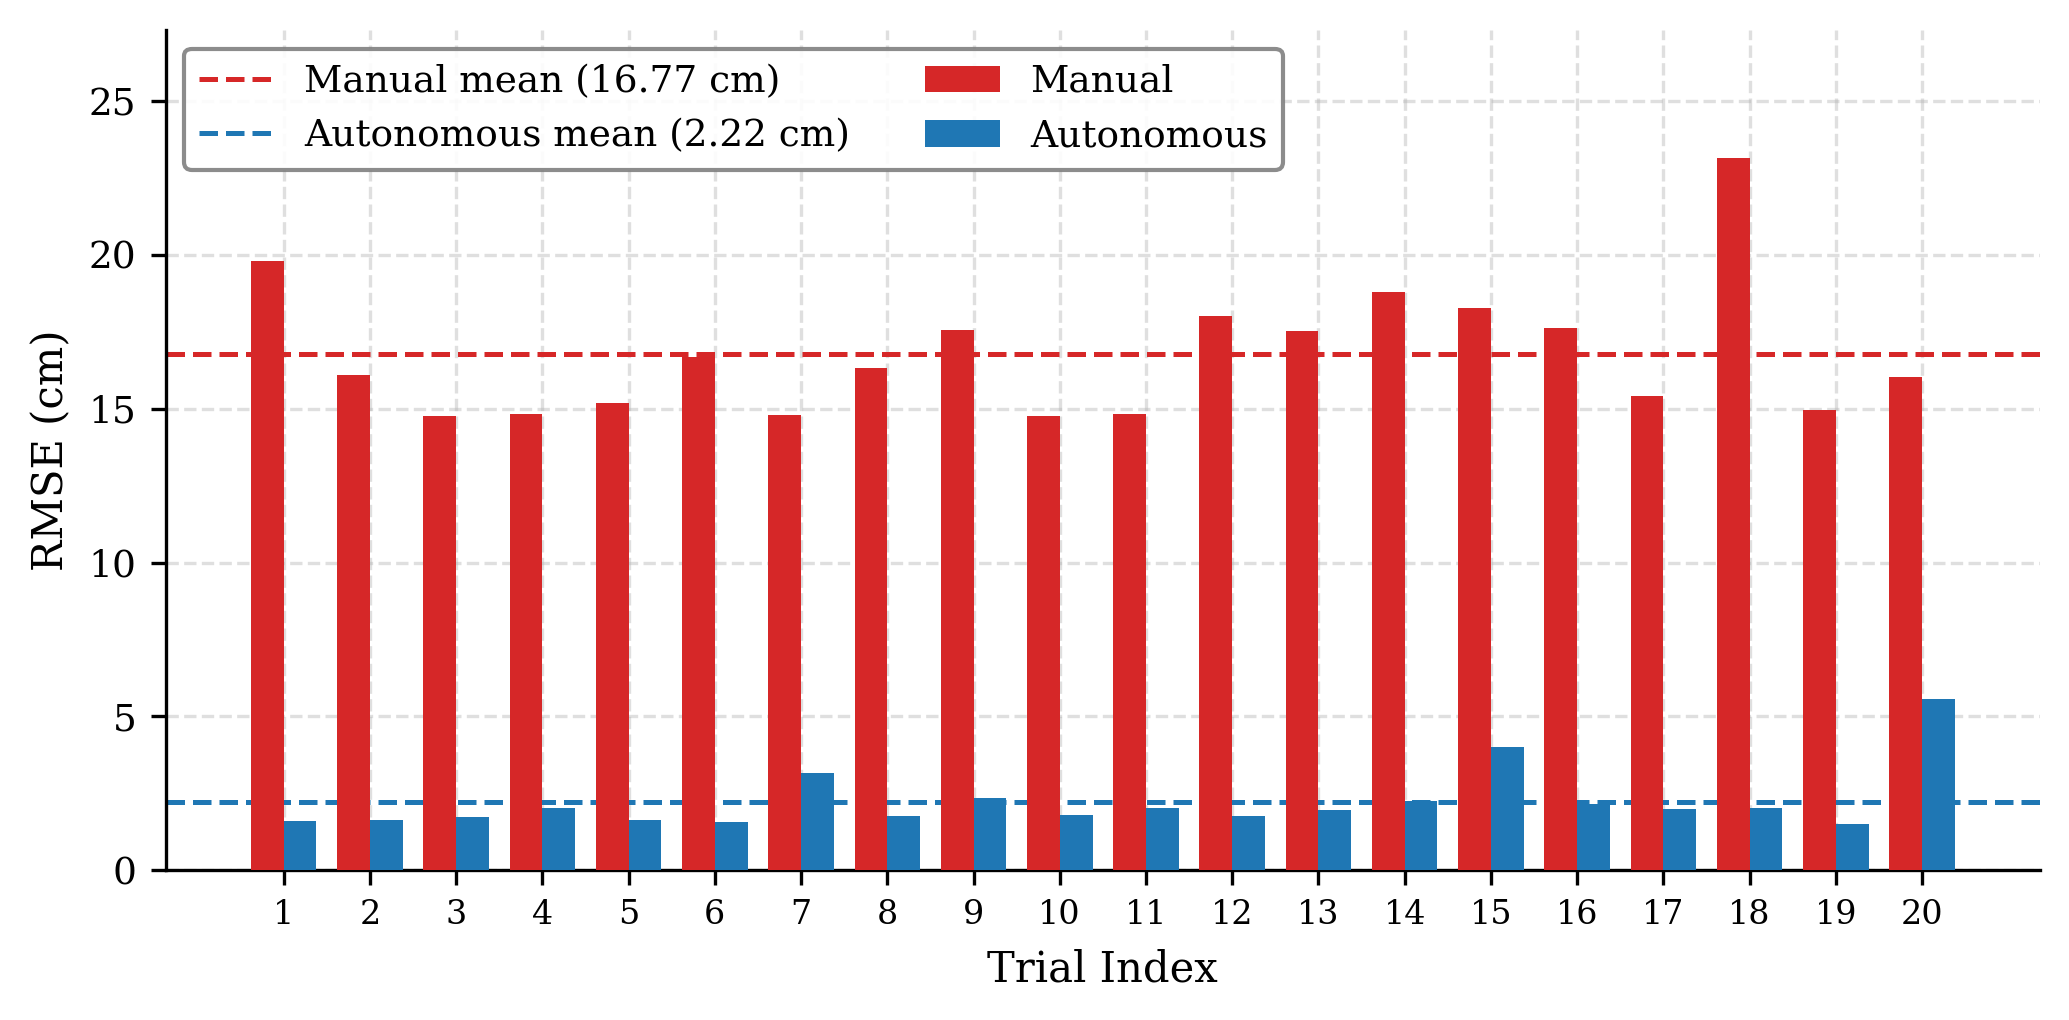

Saved → plot_per_trial_rmse_bar.png


In [3]:
# ── CELL 3: Per-Trial RMSE Bar Chart ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 3.5))

x      = TRIAL_NOS
width  = 0.38

bars_m = ax.bar(x - width/2, man_rmse,  width, color=C_MAN,  label="Manual",     zorder=3)
bars_a = ax.bar(x + width/2, auto_rmse, width, color=C_AUTO, label="Autonomous", zorder=3)

# Mean lines
ax.axhline(man_mean,  color=C_MAN,  linestyle="--", linewidth=1.2,
           label=f"Manual mean ({man_mean:.2f} cm)")
ax.axhline(auto_mean, color=C_AUTO, linestyle="--", linewidth=1.2,
           label=f"Autonomous mean ({auto_mean:.2f} cm)")

ax.set_xlabel("Trial Index")
ax.set_ylabel("RMSE (cm)")
ax.set_xticks(x)
ax.set_xticklabels(x, fontsize=8)
ax.set_ylim(0, max(man_rmse) * 1.18)
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray", ncol=2)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("plot_per_trial_rmse_bar.png")
plt.show()
print("Saved → plot_per_trial_rmse_bar.png")

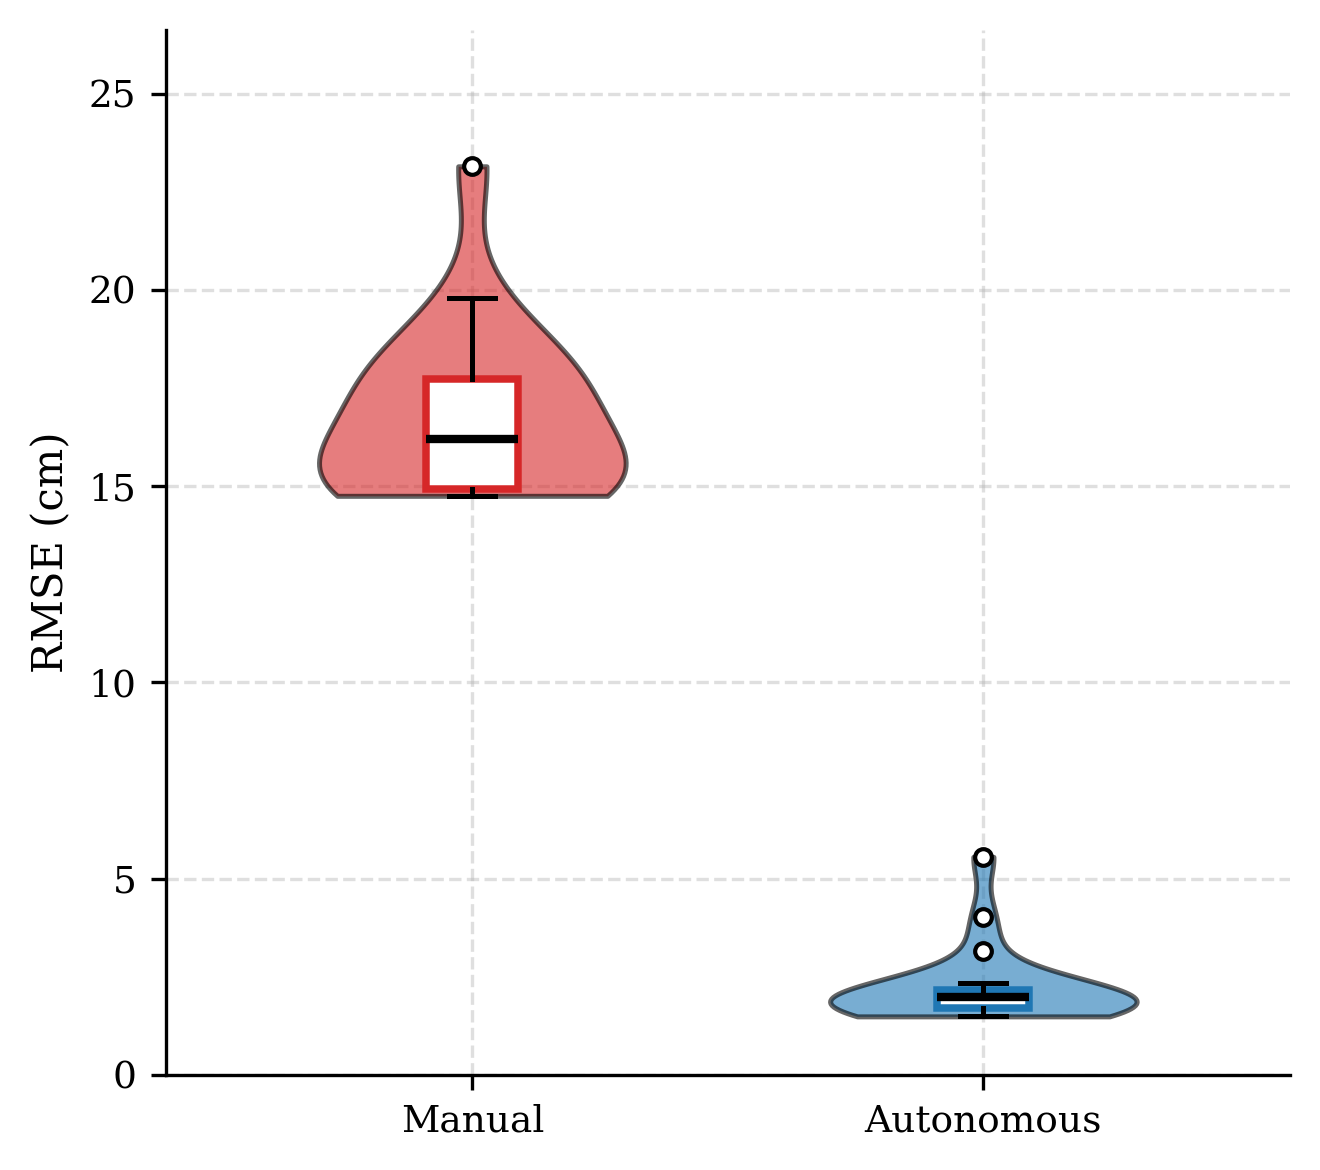

Saved → plot_violin_box.png


In [4]:
# ── CELL 4: Violin + Boxplot ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4.5, 4))

data   = [man_rmse, auto_rmse]
labels = ["Manual", "Autonomous"]
colors = [C_MAN, C_AUTO]

parts = ax.violinplot(data, positions=[1, 2], widths=0.6,
                      showmeans=False, showmedians=False, showextrema=False)

for pc, col in zip(parts["bodies"], colors):
    pc.set_facecolor(col)
    pc.set_edgecolor("black")
    pc.set_alpha(0.6)
    pc.set_linewidth(1.2)

# Boxplot overlay
bp = ax.boxplot(data, positions=[1, 2], widths=0.18,
                patch_artist=True, notch=False,
                medianprops=dict(color="black", linewidth=2),
                whiskerprops=dict(color="black", linewidth=1.2),
                capprops=dict(color="black", linewidth=1.2),
                flierprops=dict(marker="o", markersize=4,
                                markeredgecolor="black", markerfacecolor="white"))
for patch, col in zip(bp["boxes"], colors):
    patch.set_facecolor("white")
    patch.set_edgecolor(col)
    patch.set_linewidth(1.8)

ax.set_xticks([1, 2])
ax.set_xticklabels(labels)
ax.set_ylabel("RMSE (cm)")
ax.set_xlim(0.4, 2.6)
ax.set_ylim(0, max(man_rmse) * 1.15)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("plot_violin_box.png")
plt.show()
print("Saved → plot_violin_box.png")

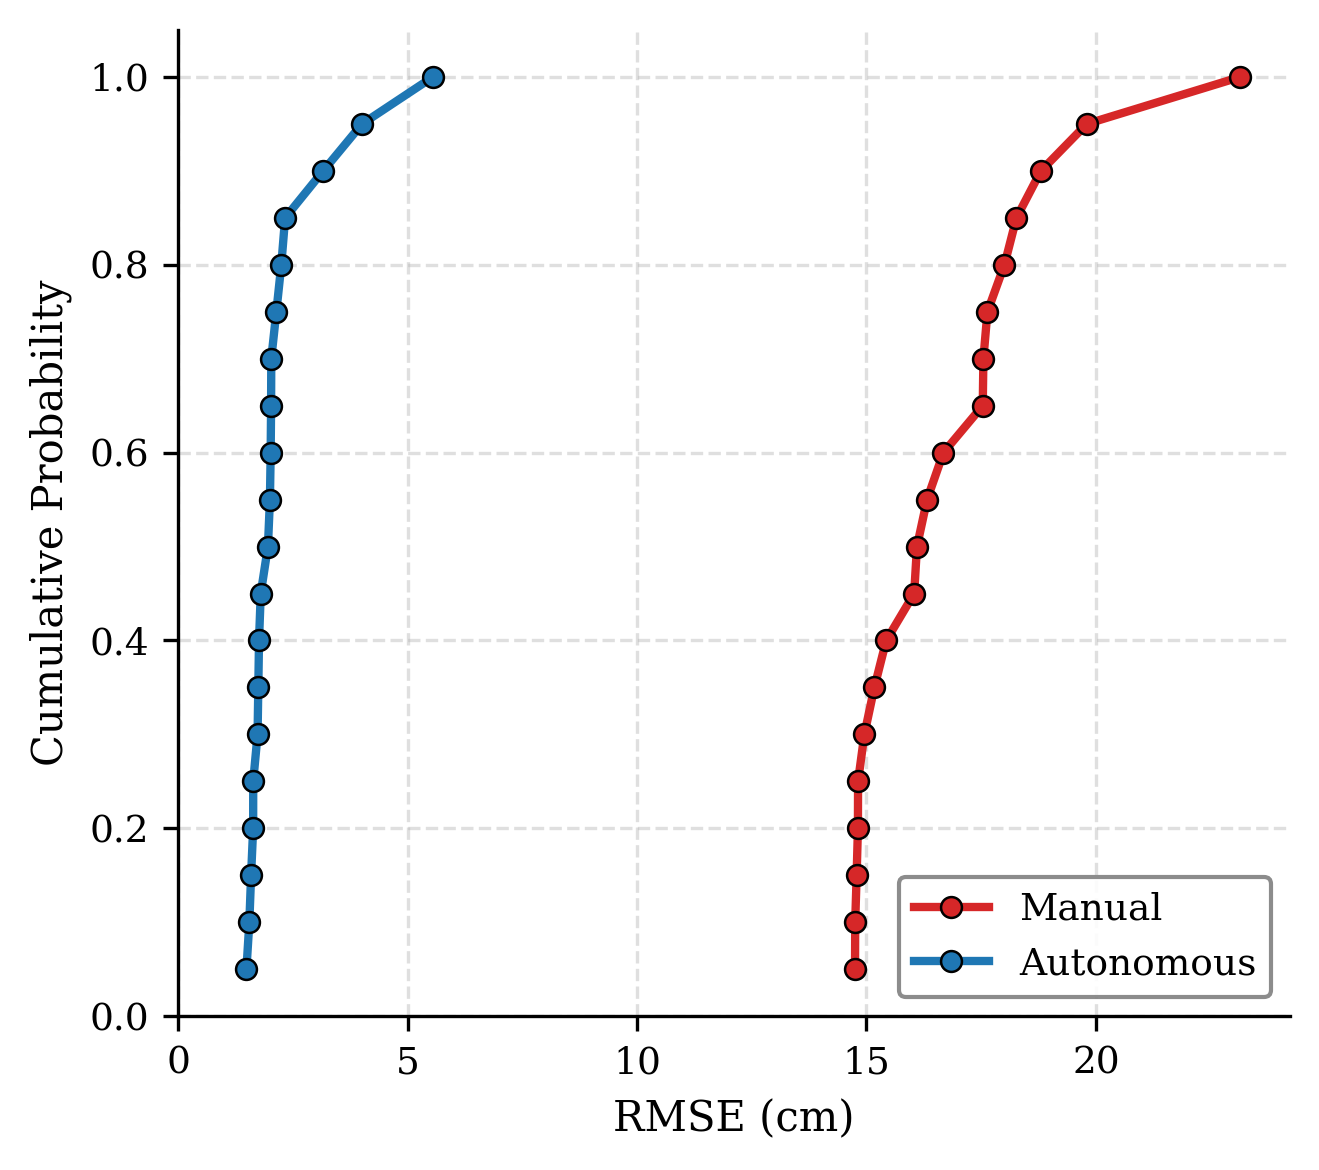

Saved → plot_cdf.png


In [7]:
# ── CELL 5: Empirical CDF ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4.5, 4))

for rmse, col, lbl in [(man_rmse, C_MAN, "Manual"), (auto_rmse, C_AUTO, "Autonomous")]:
    sorted_vals = np.sort(rmse)
    cdf         = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    ax.plot(sorted_vals, cdf, color=col, linewidth=2, label=lbl, marker="o",
            markersize=5, markeredgecolor="black", markeredgewidth=0.6)

ax.set_xlabel("RMSE (cm)")
ax.set_ylabel("Cumulative Probability")
ax.set_ylim(0, 1.05)
ax.set_xlim(left=0)
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray")
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.xaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("plot_cdf.png")
plt.show()
print("Saved → plot_cdf.png")

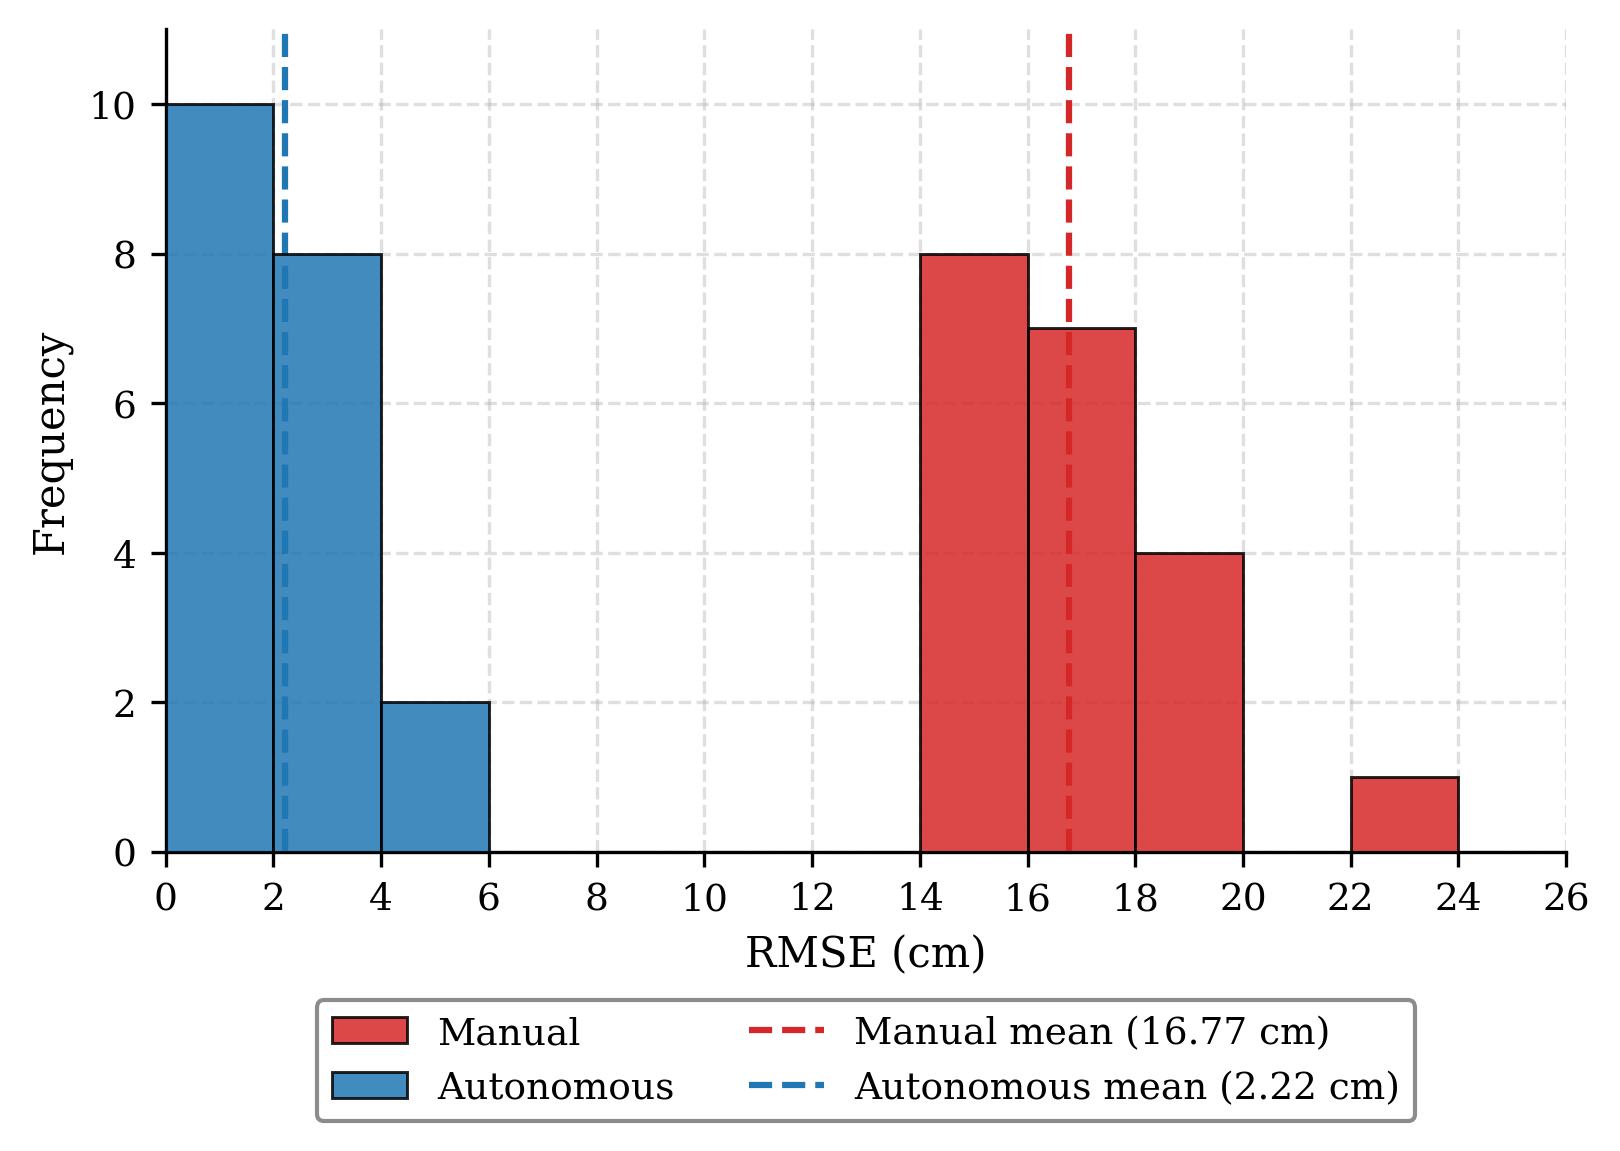

Saved → plot_histogram.png


In [9]:
# ── CELL 6: Error Histogram (fixed v2) ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, 4))

# Shared x range, split into two bin regions so bars are well-proportioned
all_vals = np.concatenate([man_rmse, auto_rmse])
bins = np.linspace(0, 26, 14)   # 13 equal bins across full range

ax.hist(man_rmse,  bins=bins, color=C_MAN,  alpha=0.85, label="Manual",
        edgecolor="black", linewidth=0.7, zorder=3)
ax.hist(auto_rmse, bins=bins, color=C_AUTO, alpha=0.85, label="Autonomous",
        edgecolor="black", linewidth=0.7, zorder=3)

ax.axvline(man_mean,  color=C_MAN,  linestyle="--", linewidth=1.5,
           label=f"Manual mean ({man_mean:.2f} cm)")
ax.axvline(auto_mean, color=C_AUTO, linestyle="--", linewidth=1.5,
           label=f"Autonomous mean ({auto_mean:.2f} cm)")

ax.set_xlabel("RMSE (cm)")
ax.set_ylabel("Frequency")
ax.set_xlim(0, 26)
ax.set_ylim(0, 11)
ax.set_xticks(np.arange(0, 27, 2))
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# Legend below the axes
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_histogram.png", bbox_inches="tight")
plt.show()
print("Saved → plot_histogram.png")

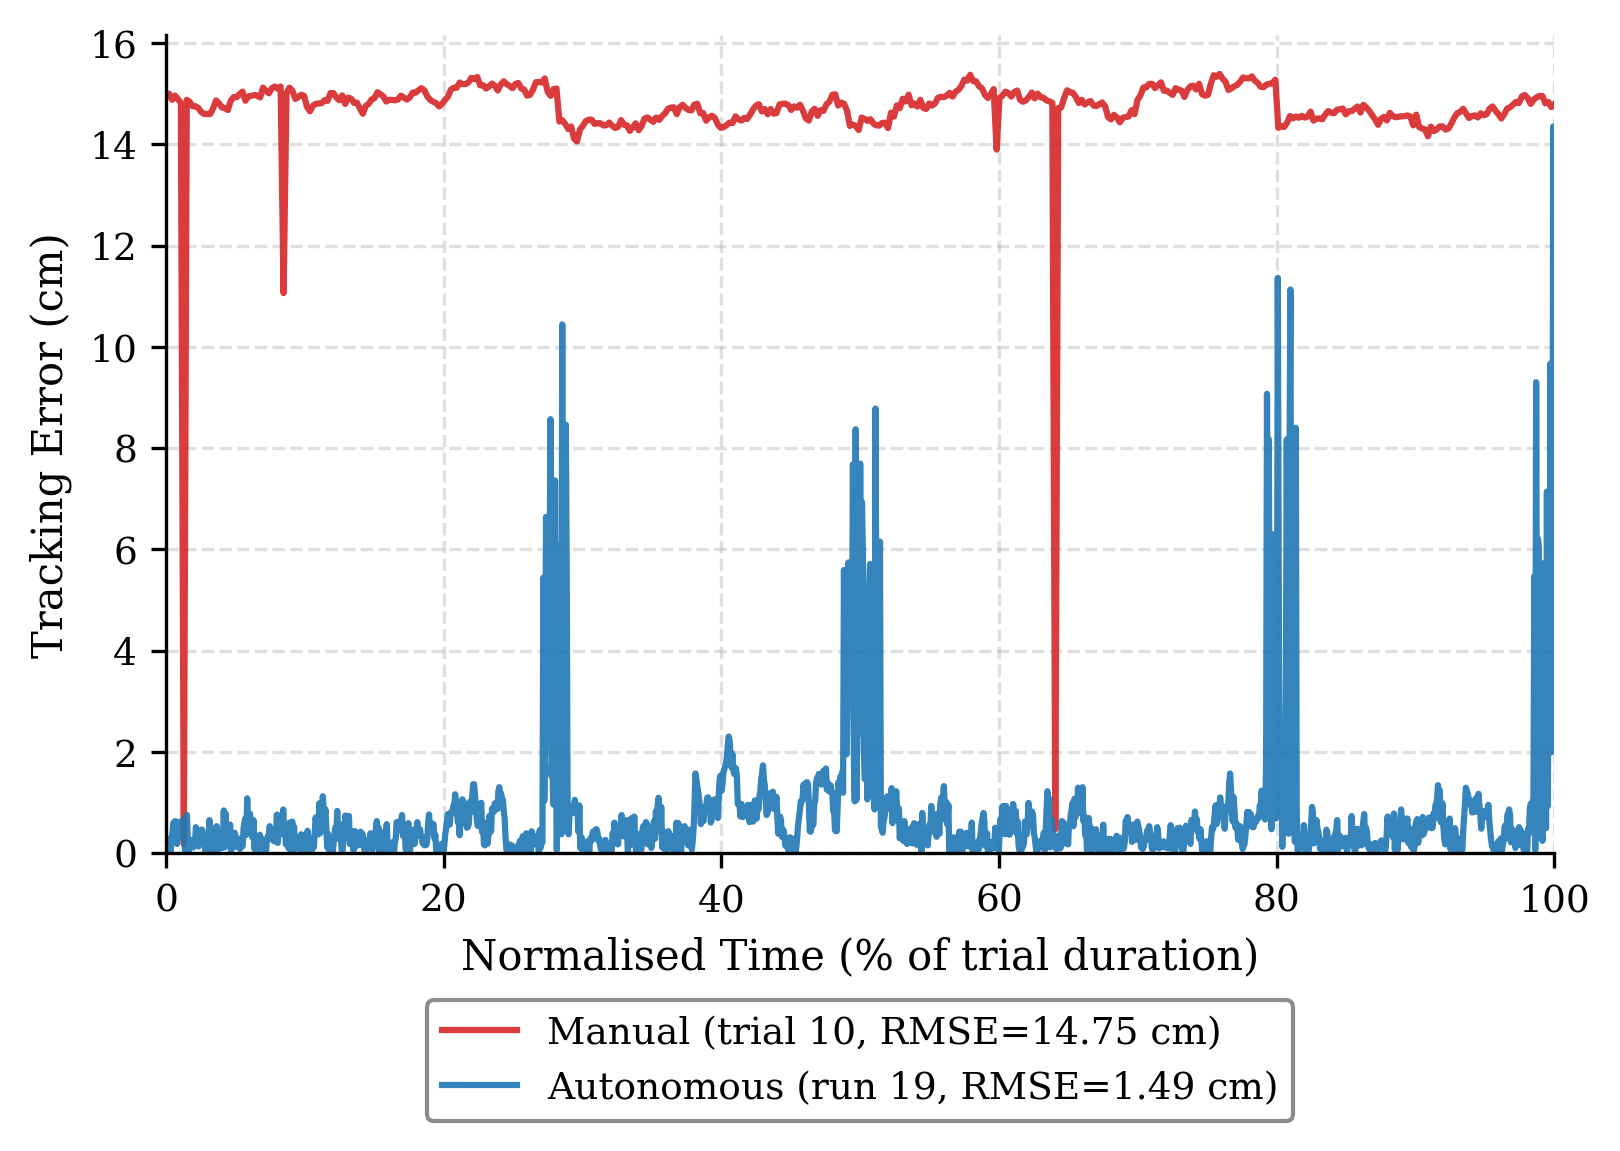

Saved → plot_error_over_time_best.png


In [10]:
# ── CELL 7: Error Over Time — Best Trial Overlay ──────────────────────────────
df_man_best  = man_dfs[man_best_idx].copy()
df_auto_best = auto_dfs[auto_best_idx].copy()

# Normalise time to [0, 100] % so both trials share same x-axis
df_man_best["t_pct"]  = np.linspace(0, 100, len(df_man_best))
df_auto_best["t_pct"] = np.linspace(0, 100, len(df_auto_best))

fig, ax = plt.subplots(figsize=(5.5, 4))

ax.plot(df_man_best["t_pct"],  df_man_best["error_cm"],
        color=C_MAN,  linewidth=1.5, alpha=0.9,
        label=f"Manual (trial {man_best_idx+1}, RMSE={man_rmse[man_best_idx]:.2f} cm)")

ax.plot(df_auto_best["t_pct"], df_auto_best["error_distance"],
        color=C_AUTO, linewidth=1.5, alpha=0.9,
        label=f"Autonomous (run {auto_best_idx+1}, RMSE={auto_rmse[auto_best_idx]:.2f} cm)")

ax.set_xlabel("Normalised Time (% of trial duration)")
ax.set_ylabel("Tracking Error (cm)")
ax.set_xlim(0, 100)
ax.set_ylim(bottom=0)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.xaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=1, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_error_over_time_best.png", bbox_inches="tight")
plt.show()
print("Saved → plot_error_over_time_best.png")

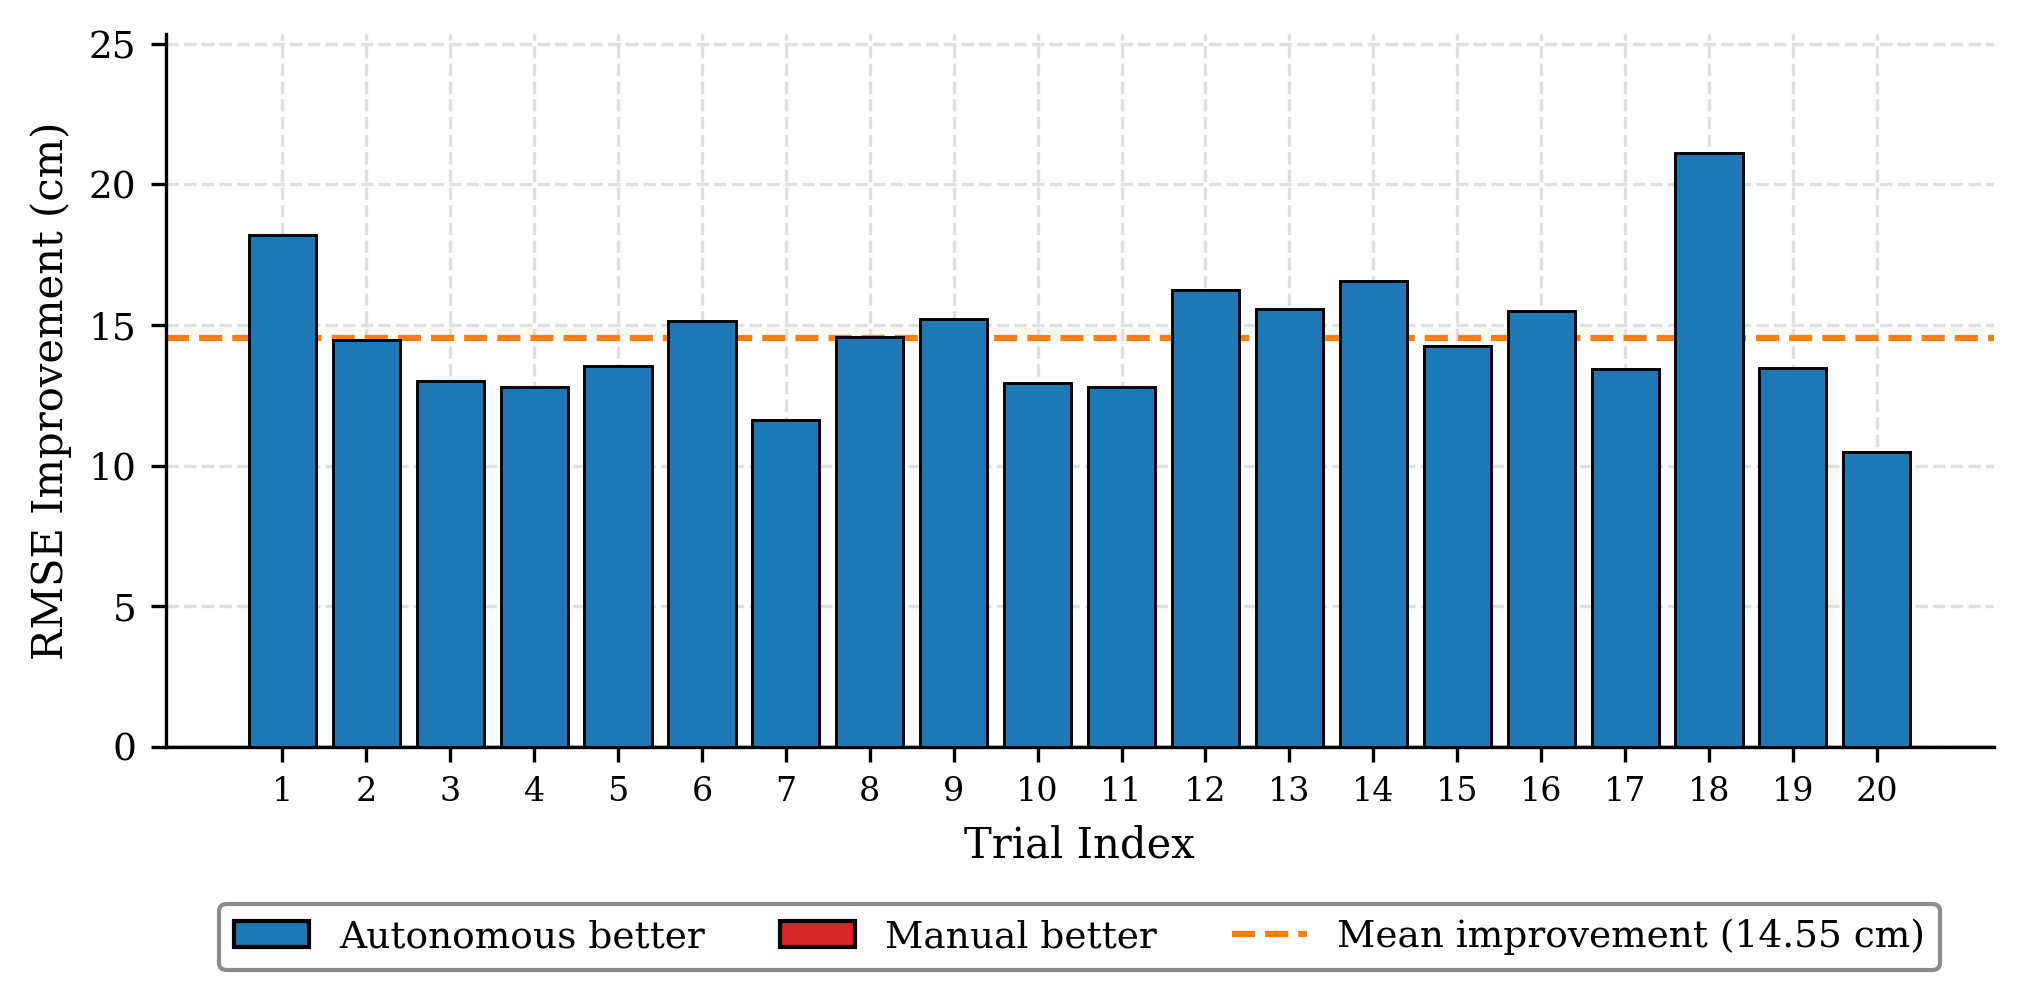

Saved → plot_waterfall_improvement.png


In [11]:
# ── CELL 8: Waterfall — RMSE Improvement Per Trial ───────────────────────────
improvement = man_rmse - auto_rmse   # positive = autonomous is better

fig, ax = plt.subplots(figsize=(7, 3.5))

colors = [C_AUTO if v >= 0 else C_MAN for v in improvement]

bars = ax.bar(TRIAL_NOS, improvement, color=colors,
              edgecolor="black", linewidth=0.7, zorder=3)

ax.axhline(improvement.mean(), color=C_DIFF, linestyle="--", linewidth=1.5,
           label=f"Mean improvement ({improvement.mean():.2f} cm)")

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xlabel("Trial Index")
ax.set_ylabel("RMSE Improvement (cm)")
ax.set_xticks(TRIAL_NOS)
ax.set_xticklabels(TRIAL_NOS, fontsize=8)
ax.set_ylim(0, improvement.max() * 1.2)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# Proxy patches for legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=C_AUTO, edgecolor="black", label="Autonomous better"),
    Patch(facecolor=C_MAN,  edgecolor="black", label="Manual better"),
    plt.Line2D([0], [0], color=C_DIFF, linestyle="--",
               linewidth=1.5, label=f"Mean improvement ({improvement.mean():.2f} cm)")
]
ax.legend(handles=legend_elements, frameon=True, framealpha=0.9,
          edgecolor="gray", loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=3, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_waterfall_improvement.png", bbox_inches="tight")
plt.show()
print("Saved → plot_waterfall_improvement.png")

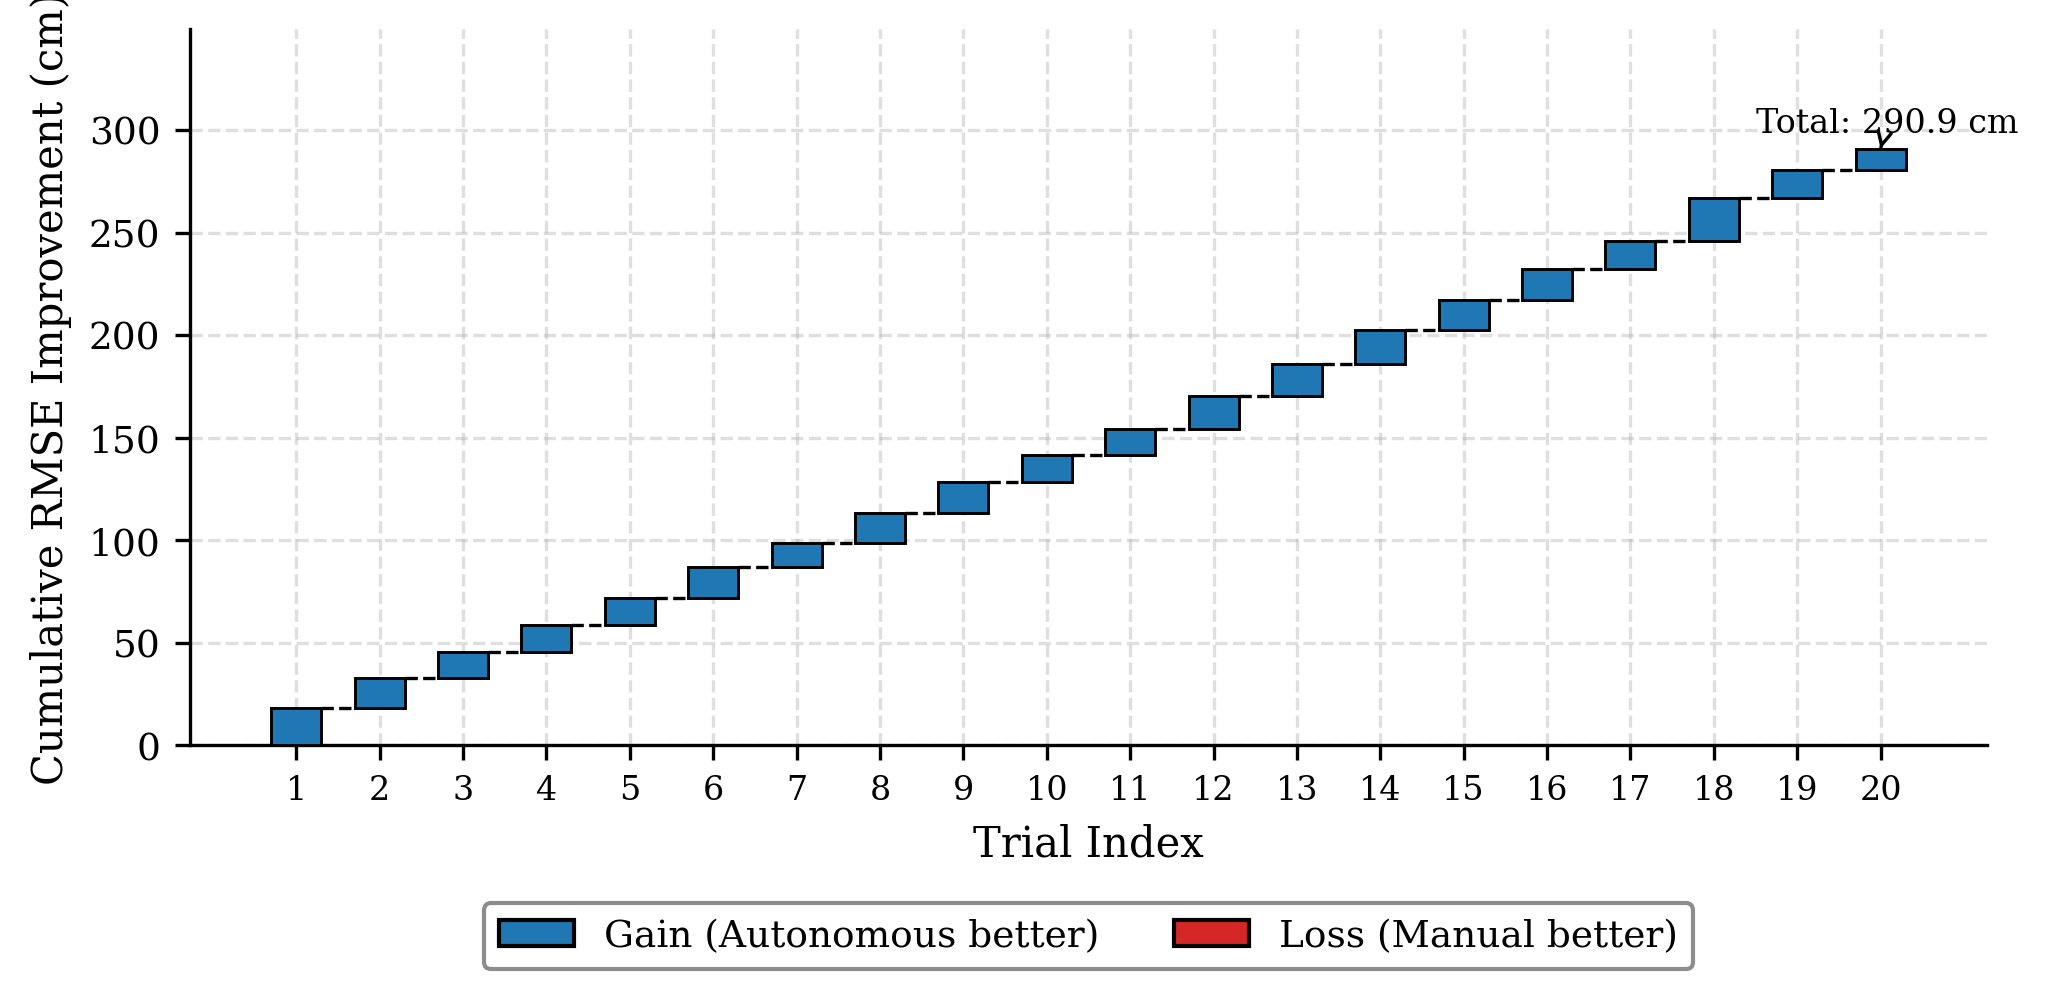

Saved → plot_waterfall_cumulative.png


In [12]:
# ── CELL 8: True Waterfall — Cumulative RMSE Improvement ─────────────────────
improvement  = man_rmse - auto_rmse          # per-trial gain
cumulative   = np.cumsum(improvement)        # running total
bottoms      = np.concatenate([[0], cumulative[:-1]])  # bar starts

fig, ax = plt.subplots(figsize=(7, 3.5))

for i, (bot, val) in enumerate(zip(bottoms, improvement)):
    col = C_AUTO if val >= 0 else C_MAN
    ax.bar(TRIAL_NOS[i], val, bottom=bot, color=col,
           edgecolor="black", linewidth=0.7, zorder=3, width=0.6)

# Connector lines between tops of bars
tops = bottoms + improvement
for i in range(len(tops) - 1):
    ax.plot([TRIAL_NOS[i] + 0.3, TRIAL_NOS[i+1] - 0.3],
            [tops[i], tops[i]], color="black", linewidth=0.8,
            linestyle="--", zorder=4)

# Final cumulative total annotation
ax.annotate(f"Total: {cumulative[-1]:.1f} cm",
            xy=(TRIAL_NOS[-1], tops[-1]),
            xytext=(TRIAL_NOS[-1] - 1.5, tops[-1] + 8),
            fontsize=8, color="black",
            arrowprops=dict(arrowstyle="->", color="black", lw=0.8))

ax.set_xlabel("Trial Index")
ax.set_ylabel("Cumulative RMSE Improvement (cm)")
ax.set_xticks(TRIAL_NOS)
ax.set_xticklabels(TRIAL_NOS, fontsize=8)
ax.set_ylim(0, cumulative.max() * 1.2)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=C_AUTO, edgecolor="black", label="Gain (Autonomous better)"),
    Patch(facecolor=C_MAN,  edgecolor="black", label="Loss (Manual better)"),
]
ax.legend(handles=legend_elements, frameon=True, framealpha=0.9,
          edgecolor="gray", loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_waterfall_cumulative.png", bbox_inches="tight")
plt.show()
print("Saved → plot_waterfall_cumulative.png")

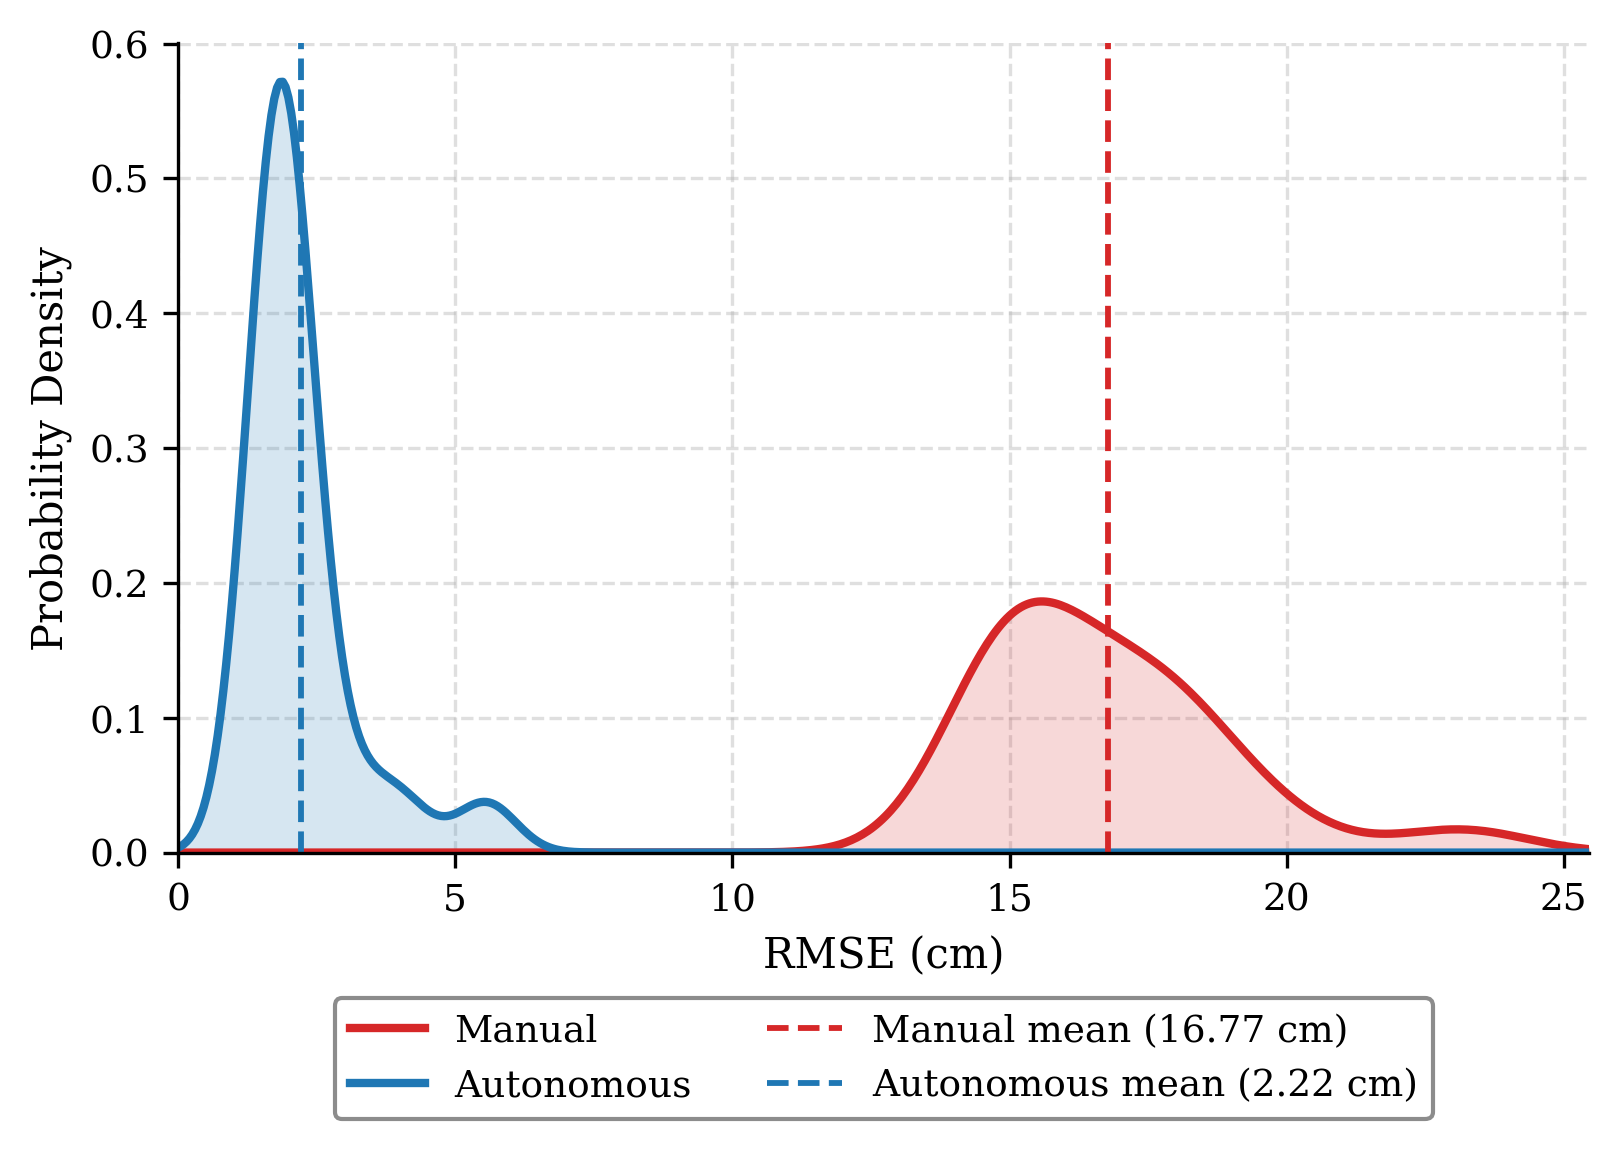

Saved → plot_kde.png


In [13]:
# ── CELL 9: KDE Density Plot ──────────────────────────────────────────────────
from scipy.stats import gaussian_kde

fig, ax = plt.subplots(figsize=(5.5, 4))

for rmse, col, lbl in [(man_rmse, C_MAN, "Manual"), (auto_rmse, C_AUTO, "Autonomous")]:
    kde    = gaussian_kde(rmse, bw_method="scott")
    x_grid = np.linspace(0, max(man_rmse) * 1.1, 500)
    y_kde  = kde(x_grid)
    ax.plot(x_grid, y_kde, color=col, linewidth=2, label=lbl)
    ax.fill_between(x_grid, y_kde, alpha=0.18, color=col)

ax.axvline(man_mean,  color=C_MAN,  linestyle="--", linewidth=1.4,
           label=f"Manual mean ({man_mean:.2f} cm)")
ax.axvline(auto_mean, color=C_AUTO, linestyle="--", linewidth=1.4,
           label=f"Autonomous mean ({auto_mean:.2f} cm)")

ax.set_xlabel("RMSE (cm)")
ax.set_ylabel("Probability Density")
ax.set_xlim(0, max(man_rmse) * 1.1)
ax.set_ylim(bottom=0)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.xaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_kde.png", bbox_inches="tight")
plt.show()
print("Saved → plot_kde.png")

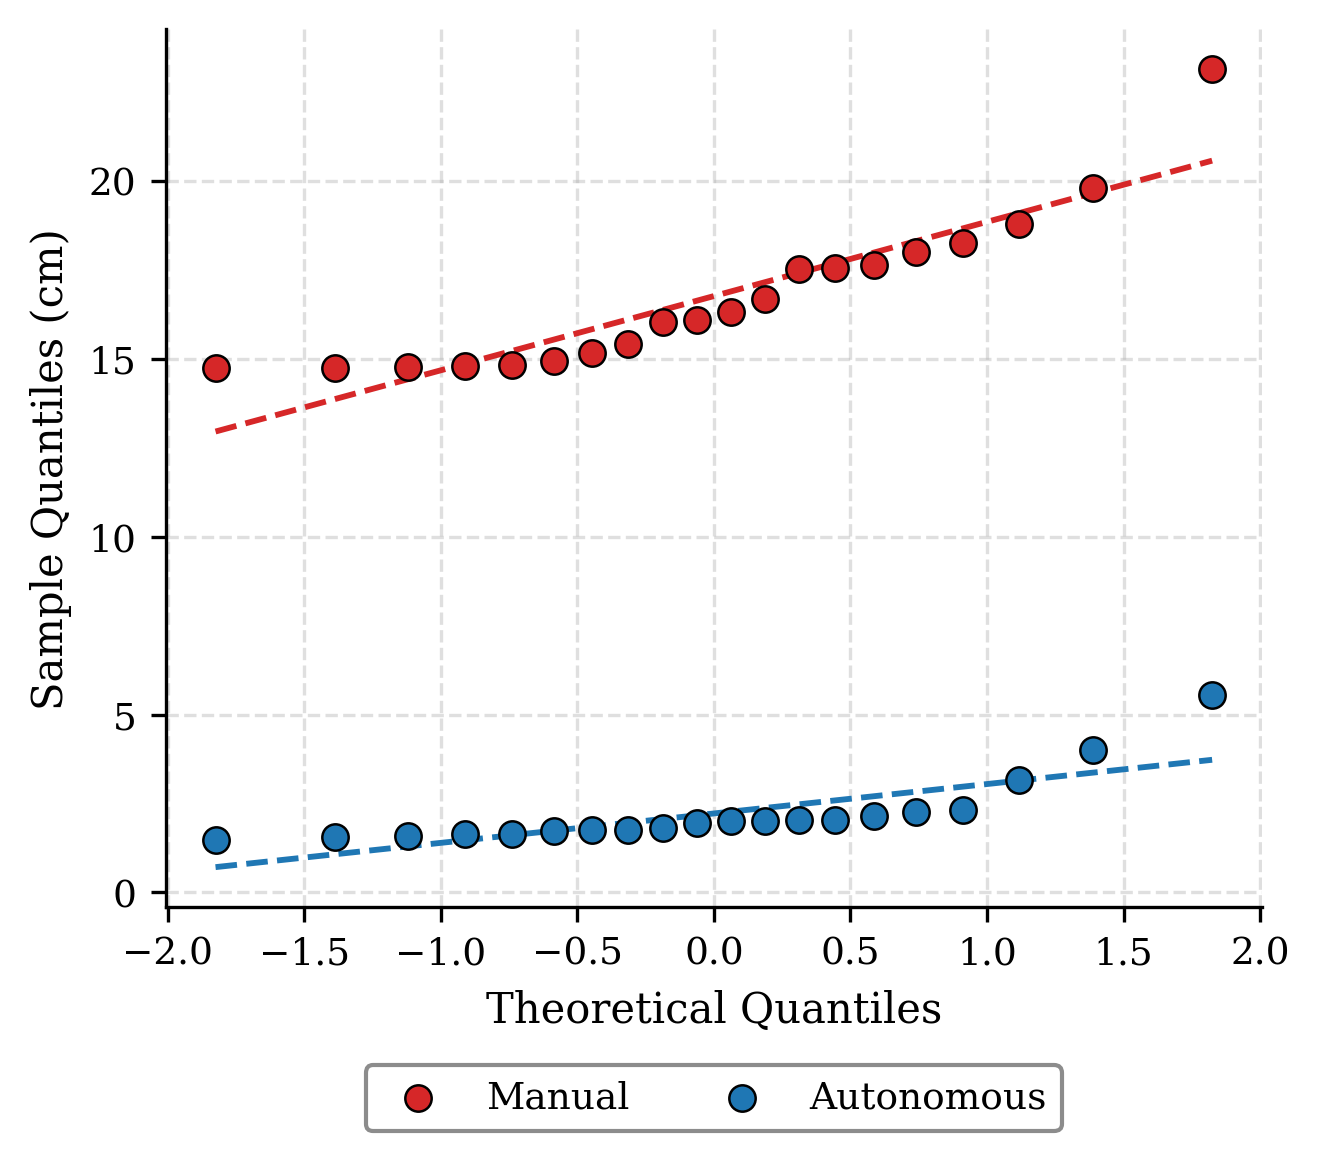

Saved → plot_qq.png


In [14]:
# ── CELL 10: Q-Q Normality Plot ───────────────────────────────────────────────
from scipy.stats import probplot

fig, ax = plt.subplots(figsize=(4.5, 4))

for rmse, col, lbl in [(man_rmse, C_MAN, "Manual"), (auto_rmse, C_AUTO, "Autonomous")]:
    (osm, osr), (slope, intercept, r) = probplot(rmse, dist="norm")
    ax.scatter(osm, osr, color=col, label=lbl,
               s=40, edgecolors="black", linewidths=0.6, zorder=4)
    x_line = np.array([osm.min(), osm.max()])
    ax.plot(x_line, slope * x_line + intercept,
            color=col, linewidth=1.4, linestyle="--", zorder=3)

ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles (cm)")
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.xaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_qq.png", bbox_inches="tight")
plt.show()
print("Saved → plot_qq.png")

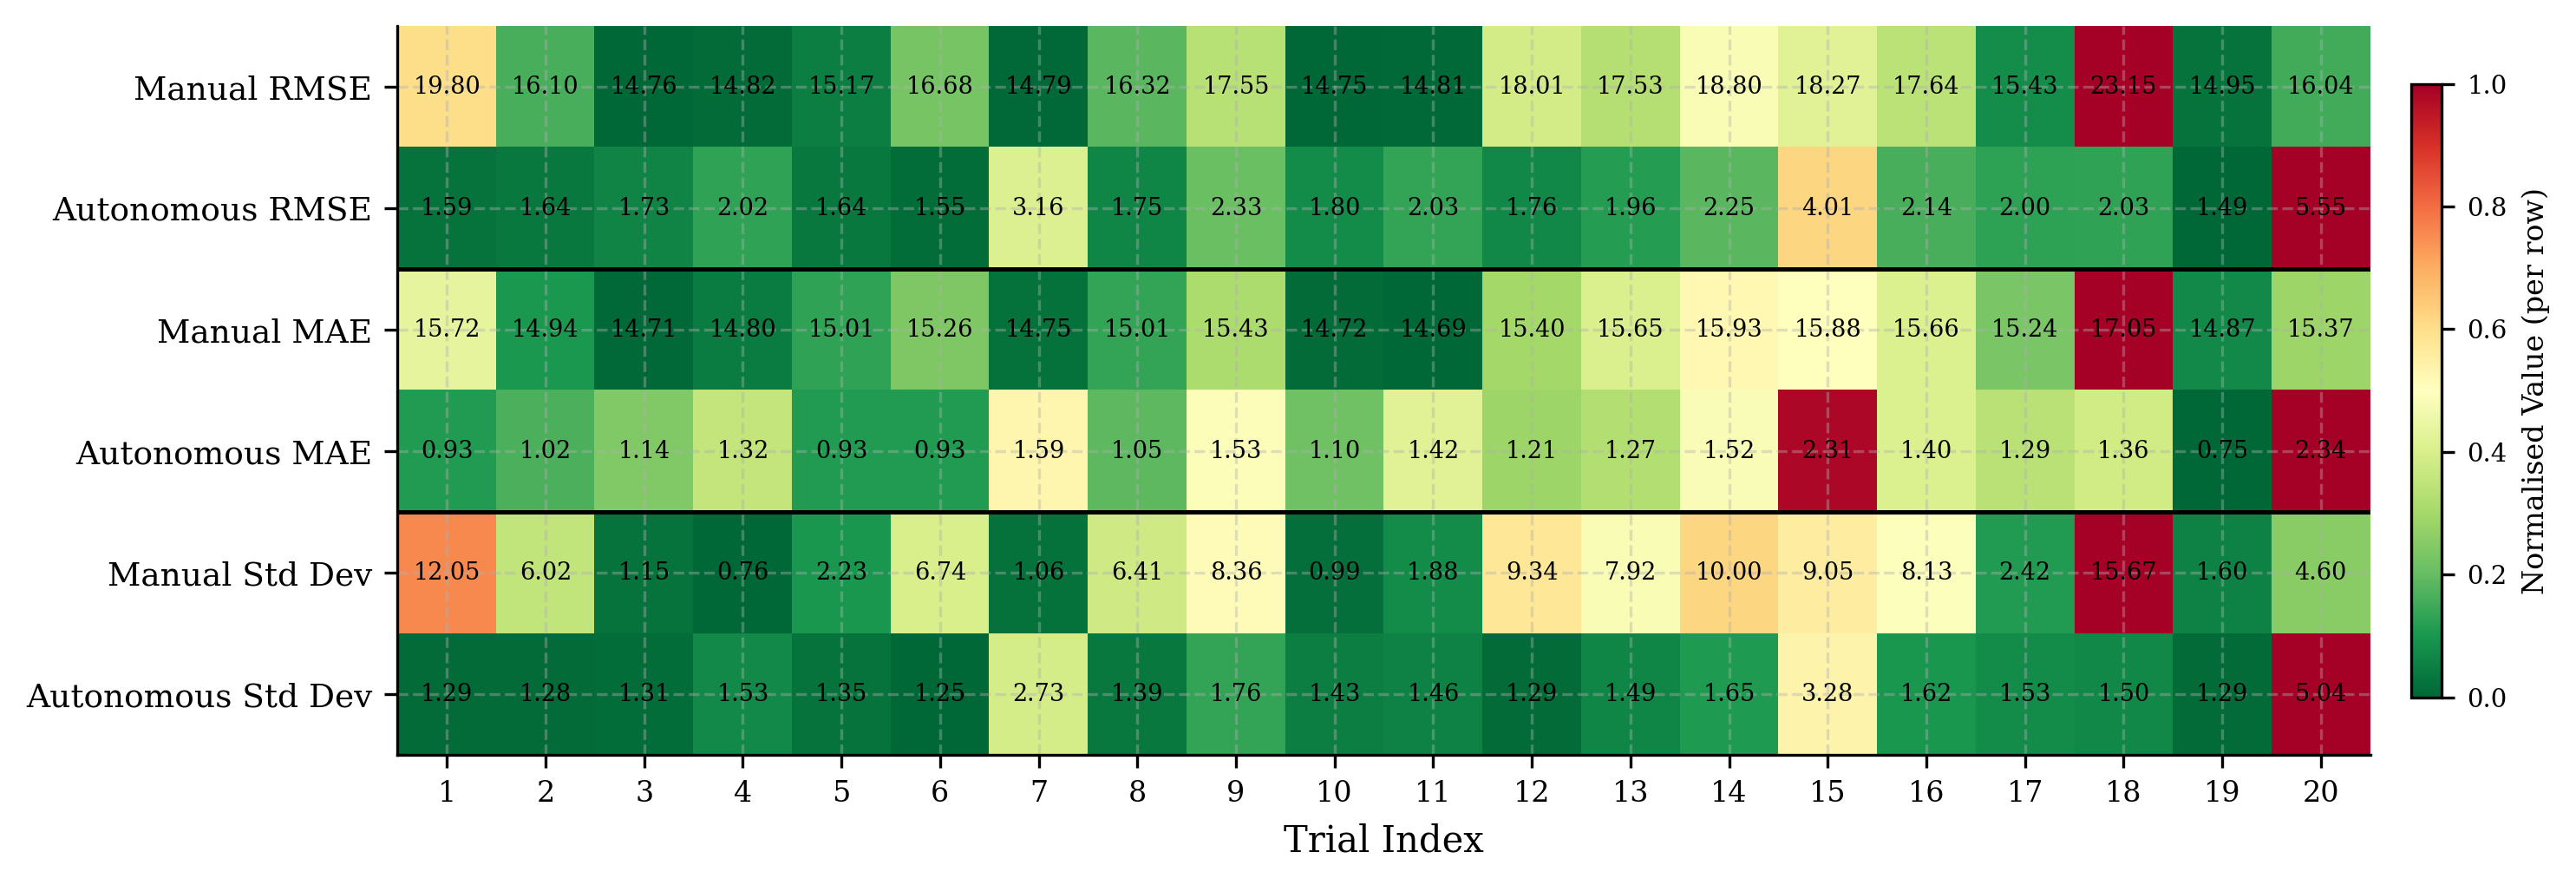

Saved → plot_heatmap.png


In [15]:
# ── CELL 11: Heatmap — Per-Trial Metrics ─────────────────────────────────────
import matplotlib.ticker as ticker

# Build metric matrix — rows = metrics, cols = trials
man_mae_per  = np.array([df["error_cm"].abs().mean()       for df in man_dfs])
auto_mae_per = np.array([df["error_distance"].abs().mean() for df in auto_dfs])
man_std_per  = np.array([df["error_cm"].std()              for df in man_dfs])
auto_std_per = np.array([df["error_distance"].std()        for df in auto_dfs])

matrix = np.vstack([
    man_rmse,
    auto_rmse,
    man_mae_per,
    auto_mae_per,
    man_std_per,
    auto_std_per,
])

row_labels = [
    "Manual RMSE",
    "Autonomous RMSE",
    "Manual MAE",
    "Autonomous MAE",
    "Manual Std Dev",
    "Autonomous Std Dev",
]

# Normalise each row to [0,1] for colour scaling
matrix_norm = (matrix - matrix.min(axis=1, keepdims=True)) / \
              (matrix.max(axis=1, keepdims=True) - matrix.min(axis=1, keepdims=True) + 1e-9)

fig, ax = plt.subplots(figsize=(10, 3.5))

im = ax.imshow(matrix_norm, aspect="auto", cmap="RdYlGn_r",
               vmin=0, vmax=1, interpolation="nearest")

# Annotate cells with actual values
for r in range(matrix.shape[0]):
    for c in range(matrix.shape[1]):
        ax.text(c, r, f"{matrix[r, c]:.2f}",
                ha="center", va="center", fontsize=6.5,
                color="black")

ax.set_xticks(np.arange(20))
ax.set_xticklabels(TRIAL_NOS, fontsize=8)
ax.set_yticks(np.arange(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=9)
ax.set_xlabel("Trial Index")

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.015, pad=0.02)
cbar.set_label("Normalised Value (per row)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# Divider line between manual and autonomous rows
for y in [1.5, 3.5]:
    ax.axhline(y, color="black", linewidth=1.2)

plt.tight_layout()
plt.savefig("plot_heatmap.png", bbox_inches="tight")
plt.show()
print("Saved → plot_heatmap.png")

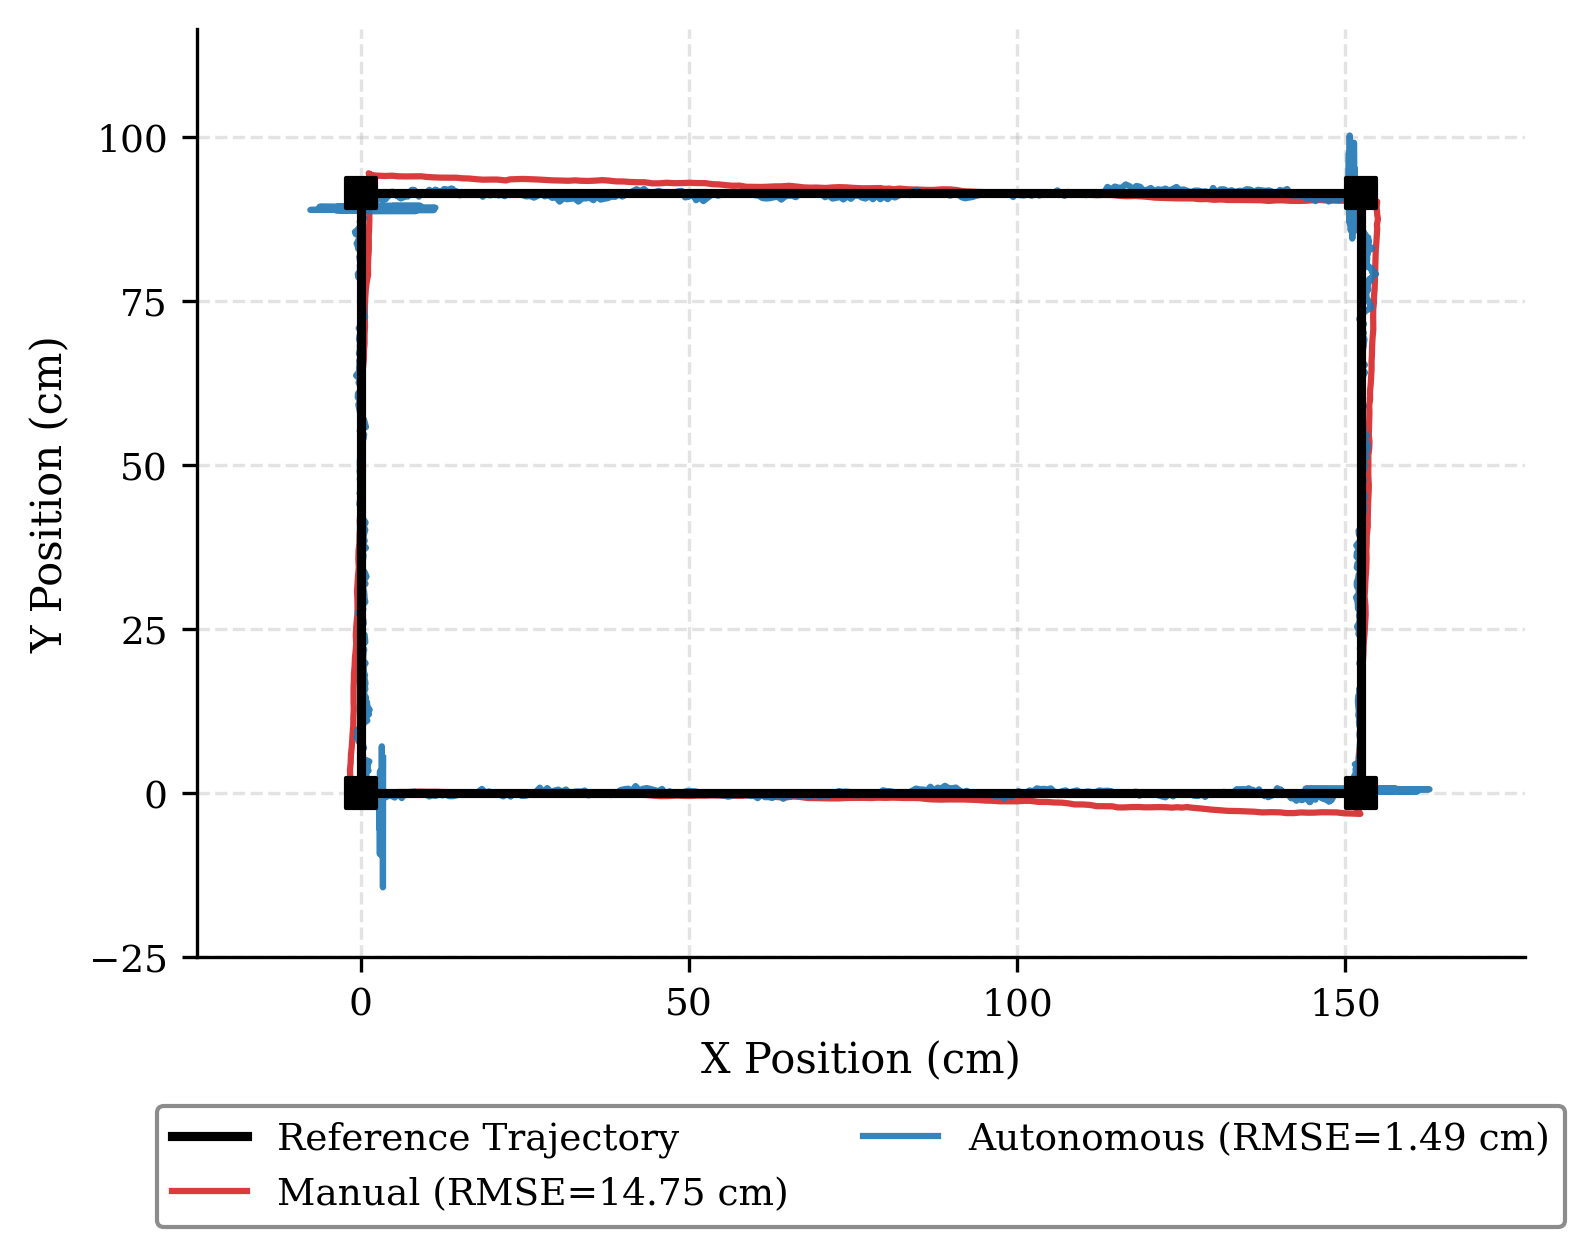

Saved → plot_path_best.png


In [17]:
# ── CELL 12: Path helper functions (run once, used by 12/13/14) ───────────────
L, W   = 152.4, 91.44          # rectangle: 5ft × 3ft in cm
rect_x = [0, L, L, 0, 0]
rect_y = [0, 0, W, W, 0]

def arc_to_xy(s, L=152.4, W=91.44):
    perim = 2 * (L + W)
    s = s % perim
    if   s <= L:           return s,         0.0
    elif s <= L + W:       return L,         s - L
    elif s <= 2*L + W:     return L-(s-(L+W)), W
    else:                  return 0.0,       W-(s-(2*L+W))

def reconstruct_auto_xy(df):
    perim  = 2 * (L + W)
    df_t   = df[df["control_state"] == "tracking"].copy() \
             if "control_state" in df.columns else df.copy()
    rx, ry = [], []
    for _, row in df_t.iterrows():
        s, dev = row["path_y"], row["robot_x"]
        px, py = arc_to_xy(s)
        s_mod  = s % perim
        if   s_mod <= L:       tan = ( 1,  0)
        elif s_mod <= L + W:   tan = ( 0,  1)
        elif s_mod <= 2*L + W: tan = (-1,  0)
        else:                  tan = ( 0, -1)
        nx, ny = -tan[1], tan[0]
        rx.append(px + dev * nx)
        ry.append(py + dev * ny)
    return np.array(rx), np.array(ry)

def normalize_manual_xy(df):
    rx = df["robot_x_cm"].values.copy()
    ry = df["robot_y_cm"].values.copy()
    rx -= rx[0];  ry -= ry[0]
    n   = max(10, len(rx) // 4)
    dx, dy = rx[n], ry[n]
    if abs(dy) > abs(dx):
        rx, ry = ry, rx
        dx, dy = dy, dx
    if dx < 0: rx = -rx
    if ry[len(ry) // 4 * 2] < 0: ry = -ry
    return rx, ry

def style_path_ax(ax):
    ax.set_xlim(-25, L + 25)
    ax.set_ylim(-25, W + 25)
    ax.set_aspect("equal")
    ax.set_xlabel("X Position (cm)")
    ax.set_ylabel("Y Position (cm)")
    ax.xaxis.set_major_locator(__import__("matplotlib").ticker.MultipleLocator(50))
    ax.yaxis.set_major_locator(__import__("matplotlib").ticker.MultipleLocator(25))
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

# ── Plot ──────────────────────────────────────────────────────────────────────
bm_x, bm_y = normalize_manual_xy(man_dfs[man_best_idx])
ba_x, ba_y  = reconstruct_auto_xy(auto_dfs[auto_best_idx])

fig, ax = plt.subplots(figsize=(5.5, 4.5))

ax.plot(rect_x, rect_y, color="black", linewidth=2.2, zorder=6,
        label="Reference Trajectory")
ax.scatter([0, L, L, 0], [0, 0, W, W],
           color="black", s=50, marker="s", zorder=7, clip_on=False)
ax.plot(bm_x, bm_y, color=C_MAN,  linewidth=1.5, alpha=0.9, zorder=4,
        label=f"Manual (RMSE={man_rmse[man_best_idx]:.2f} cm)")
ax.plot(ba_x, ba_y, color=C_AUTO, linewidth=1.5, alpha=0.9, zorder=5,
        label=f"Autonomous (RMSE={auto_rmse[auto_best_idx]:.2f} cm)")

style_path_ax(ax)
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_path_best.png", bbox_inches="tight")
plt.show()
print("Saved → plot_path_best.png")

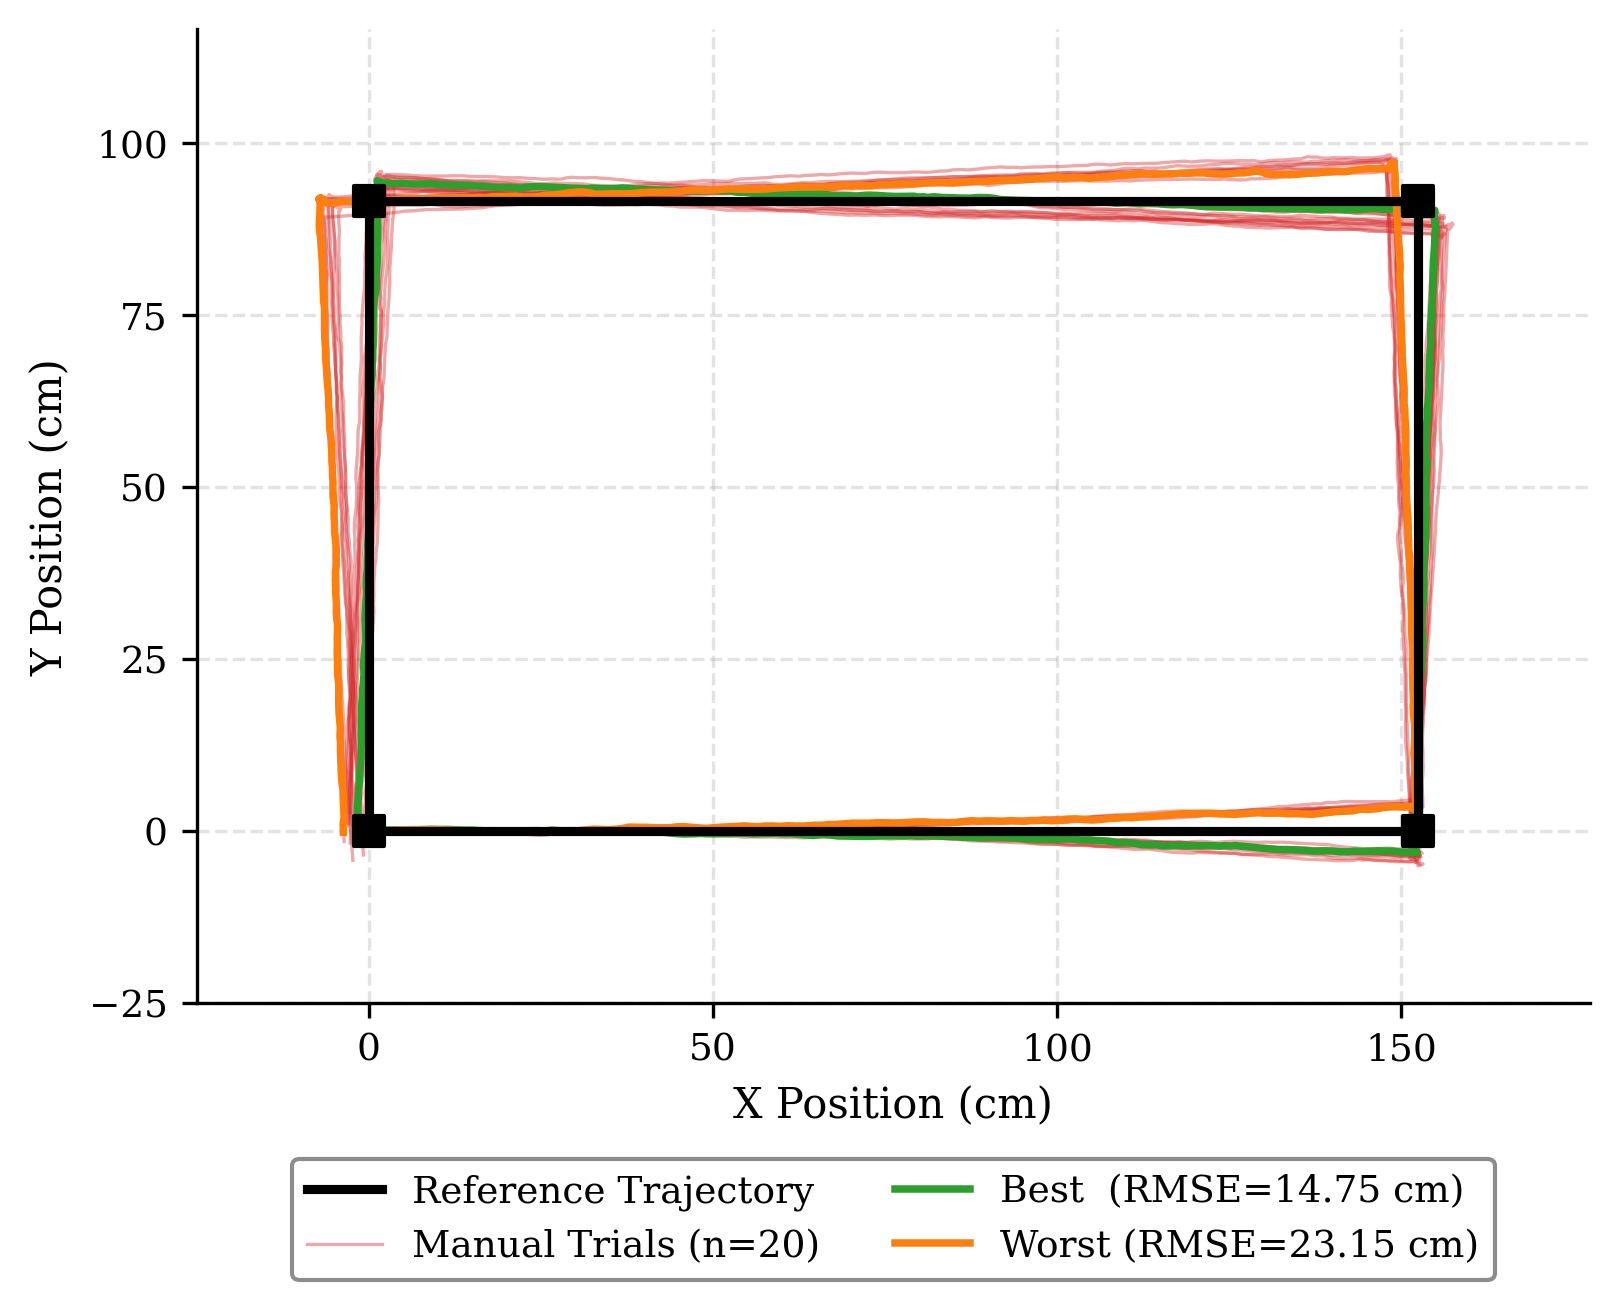

Saved → plot_path_all_manual.png


In [18]:
# ── CELL 13: All 20 Manual Paths Overlaid ────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, 4.5))

ax.plot(rect_x, rect_y, color="black", linewidth=2.2, zorder=6,
        label="Reference Trajectory")
ax.scatter([0, L, L, 0], [0, 0, W, W],
           color="black", s=50, marker="s", zorder=7, clip_on=False)

for i, df in enumerate(man_dfs):
    rx, ry = normalize_manual_xy(df)
    ax.plot(rx, ry, color=C_MAN, linewidth=0.8, alpha=0.4, zorder=3,
            label="Manual Trials (n=20)" if i == 0 else "_nolegend_")

# Highlight best and worst
bm_x, bm_y = normalize_manual_xy(man_dfs[man_best_idx])
wm_x, wm_y = normalize_manual_xy(man_dfs[man_worst_idx])

ax.plot(bm_x, bm_y, color=C_ACC,  linewidth=1.8, zorder=5,
        label=f"Best  (RMSE={man_rmse[man_best_idx]:.2f} cm)")
ax.plot(wm_x, wm_y, color=C_DIFF, linewidth=1.8, zorder=5,
        label=f"Worst (RMSE={man_rmse[man_worst_idx]:.2f} cm)")

style_path_ax(ax)
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_path_all_manual.png", bbox_inches="tight")
plt.show()
print("Saved → plot_path_all_manual.png")

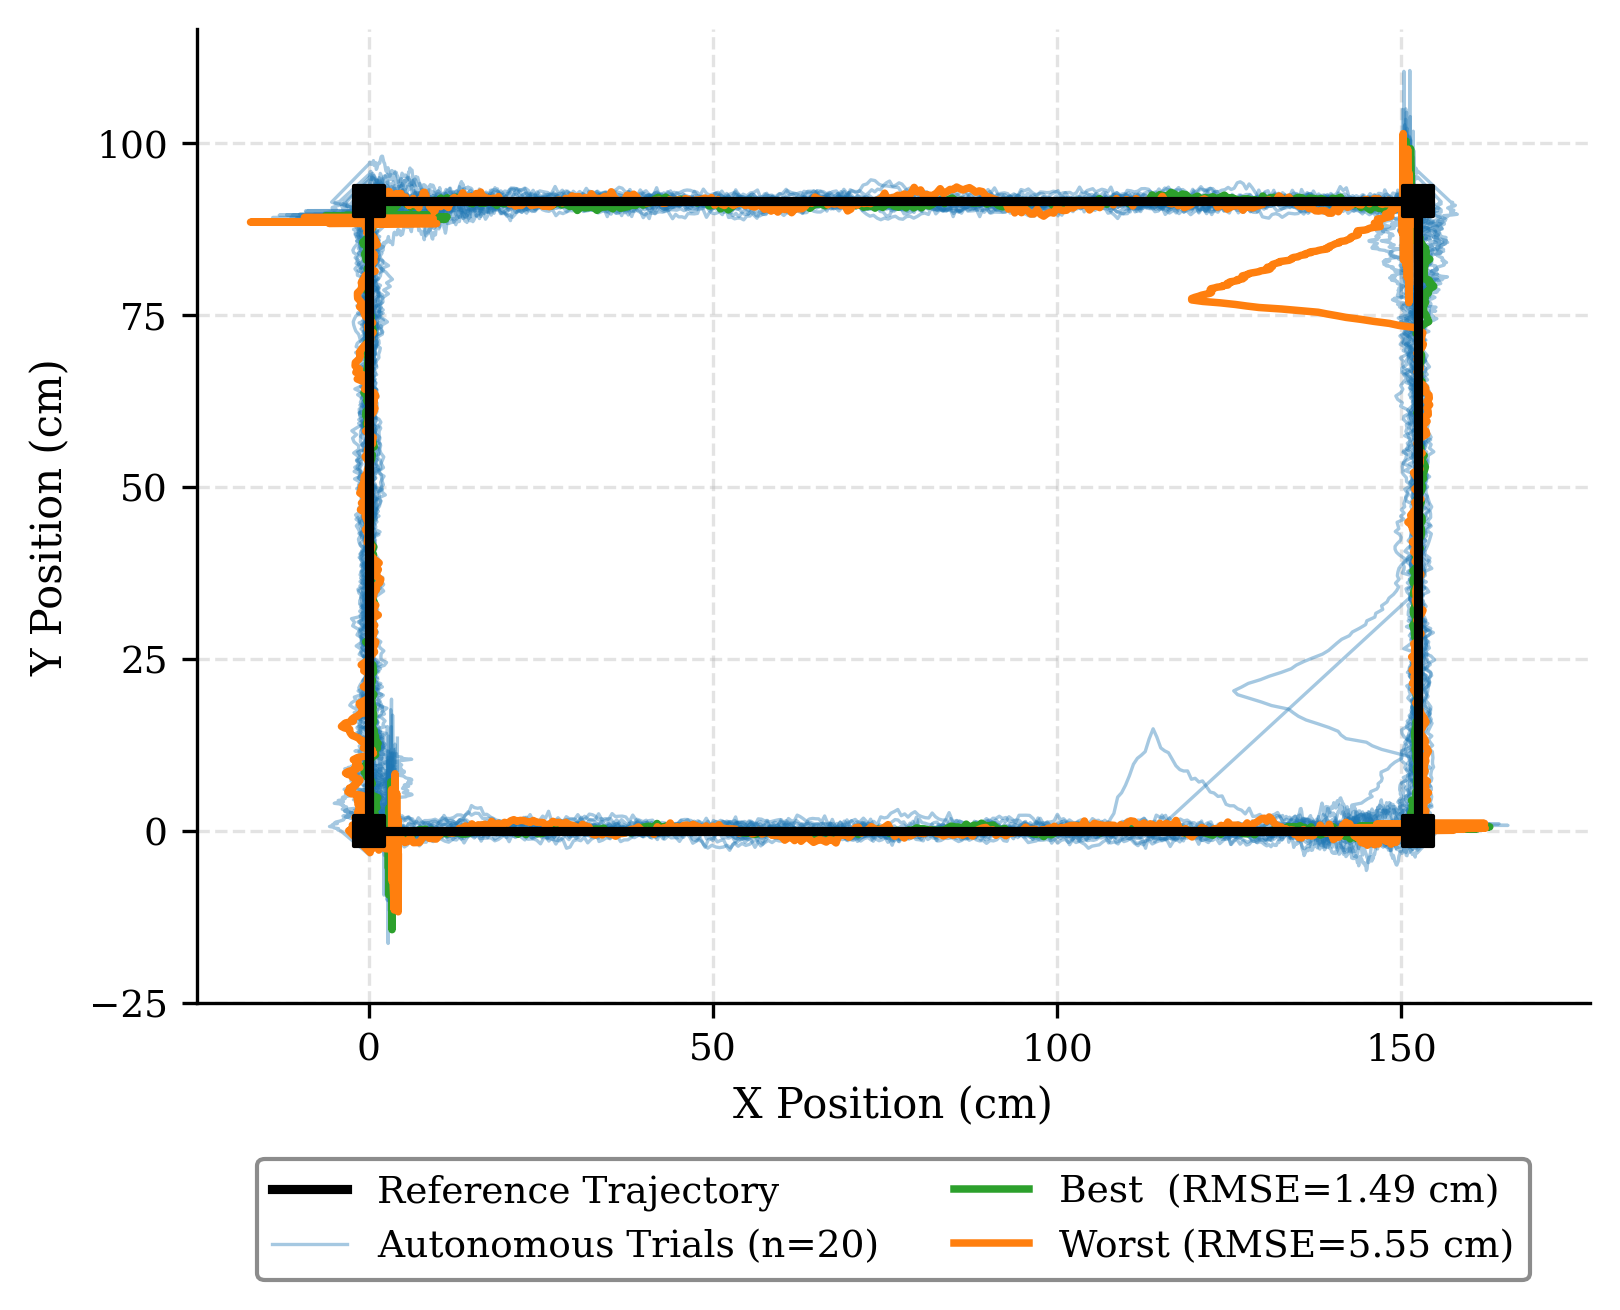

Saved → plot_path_all_autonomous.png


In [19]:
# ── CELL 14: All 20 Autonomous Paths Overlaid ─────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, 4.5))

ax.plot(rect_x, rect_y, color="black", linewidth=2.2, zorder=6,
        label="Reference Trajectory")
ax.scatter([0, L, L, 0], [0, 0, W, W],
           color="black", s=50, marker="s", zorder=7, clip_on=False)

for i, df in enumerate(auto_dfs):
    rx, ry = reconstruct_auto_xy(df)
    ax.plot(rx, ry, color=C_AUTO, linewidth=0.8, alpha=0.4, zorder=3,
            label="Autonomous Trials (n=20)" if i == 0 else "_nolegend_")

# Highlight best and worst
ba_x, ba_y = reconstruct_auto_xy(auto_dfs[auto_best_idx])
wa_x, wa_y = reconstruct_auto_xy(auto_dfs[auto_worst_idx])

ax.plot(ba_x, ba_y, color=C_ACC,  linewidth=1.8, zorder=5,
        label=f"Best  (RMSE={auto_rmse[auto_best_idx]:.2f} cm)")
ax.plot(wa_x, wa_y, color=C_DIFF, linewidth=1.8, zorder=5,
        label=f"Worst (RMSE={auto_rmse[auto_worst_idx]:.2f} cm)")

style_path_ax(ax)
ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_path_all_autonomous.png", bbox_inches="tight")
plt.show()
print("Saved → plot_path_all_autonomous.png")

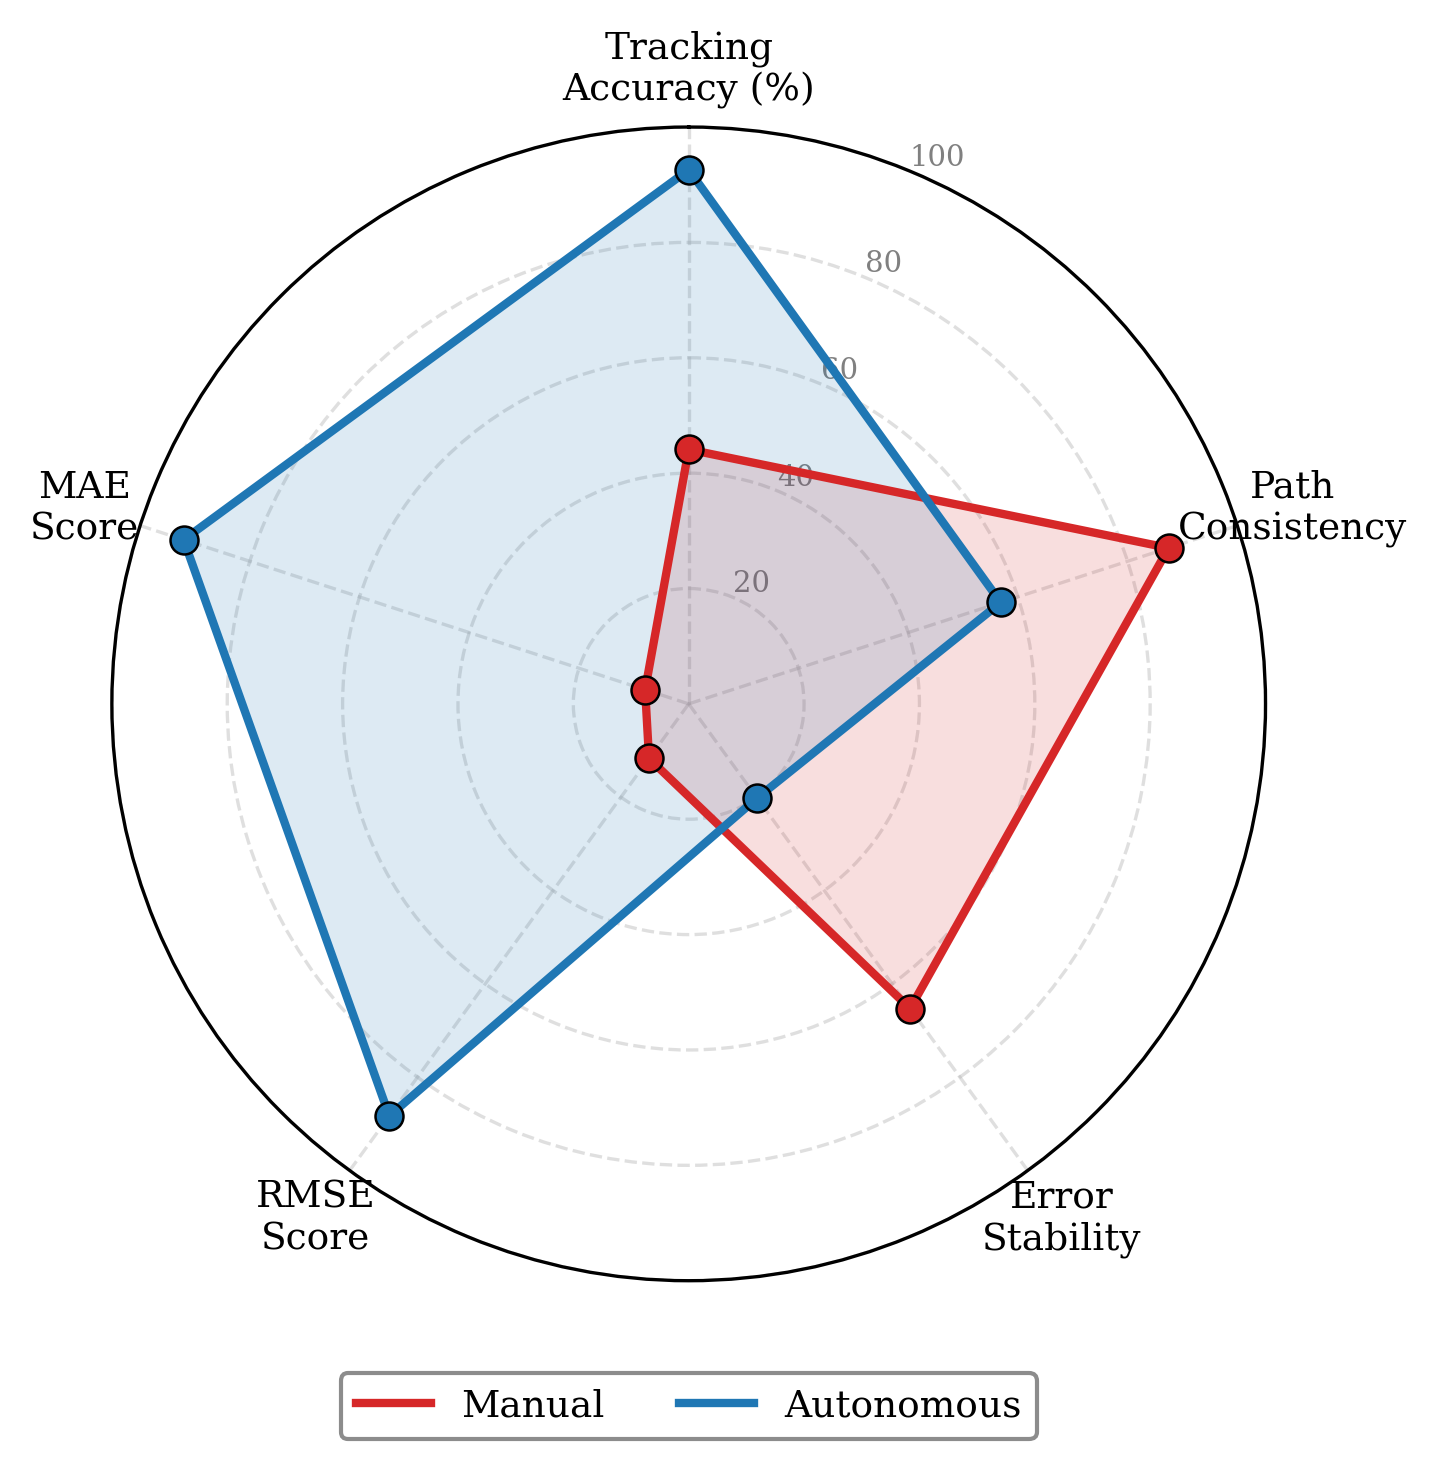

Saved → plot_radar.png


In [20]:
# ── CELL 15: Radar / Spider Chart ─────────────────────────────────────────────
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as pe

# ── Metrics (higher = better for all, so invert error-based ones) ─────────────
metrics = [
    "Tracking\nAccuracy (%)",
    "Path\nConsistency",
    "Error\nStability",
    "RMSE\nScore",
    "MAE\nScore",
]

# Normalise to [0, 100] where 100 = best possible
man_vals = np.array([
    man_acc.mean(),                                      # tracking accuracy
    (1 - man_rmse.std()  / man_rmse.mean())  * 100,     # consistency (low CV = good)
    (1 - man_std_per.mean() / man_rmse.mean()) * 100,   # error stability
    (1 - man_mean  / (man_mean  + auto_mean))  * 100,   # RMSE score
    (1 - man_mae_mean / (man_mae_mean + auto_mae_mean)) * 100,  # MAE score
])

auto_vals = np.array([
    auto_acc.mean(),
    (1 - auto_rmse.std()  / auto_rmse.mean())  * 100,
    (1 - auto_std_per.mean() / auto_rmse.mean()) * 100,
    (1 - auto_mean  / (man_mean  + auto_mean))  * 100,
    (1 - auto_mae_mean / (man_mae_mean + auto_mae_mean)) * 100,
])

# Clip to [0, 100]
man_vals  = np.clip(man_vals,  0, 100)
auto_vals = np.clip(auto_vals, 0, 100)

N      = len(metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]   # close polygon

man_plot  = man_vals.tolist()  + man_vals[:1].tolist()
auto_plot = auto_vals.tolist() + auto_vals[:1].tolist()

fig, ax = plt.subplots(figsize=(5, 5),
                        subplot_kw=dict(polar=True))

# Draw spokes and rings
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=9)
ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_yticklabels(["20", "40", "60", "80", "100"], fontsize=7, color="grey")
ax.yaxis.grid(True,  linestyle="--", alpha=0.4)
ax.xaxis.grid(True,  linestyle="--", alpha=0.4)

# Manual
ax.plot(angles, man_plot,  color=C_MAN,  linewidth=2,   zorder=4,
        label="Manual")
ax.fill(angles, man_plot,  color=C_MAN,  alpha=0.15,    zorder=3)
ax.scatter(angles[:-1], man_vals,  color=C_MAN,  s=45,
           edgecolors="black", linewidths=0.6, zorder=5)

# Autonomous
ax.plot(angles, auto_plot, color=C_AUTO, linewidth=2,   zorder=4,
        label="Autonomous")
ax.fill(angles, auto_plot, color=C_AUTO, alpha=0.15,    zorder=3)
ax.scatter(angles[:-1], auto_vals, color=C_AUTO, s=45,
           edgecolors="black", linewidths=0.6, zorder=5)

ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.08),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_radar.png", bbox_inches="tight")
plt.show()
print("Saved → plot_radar.png")

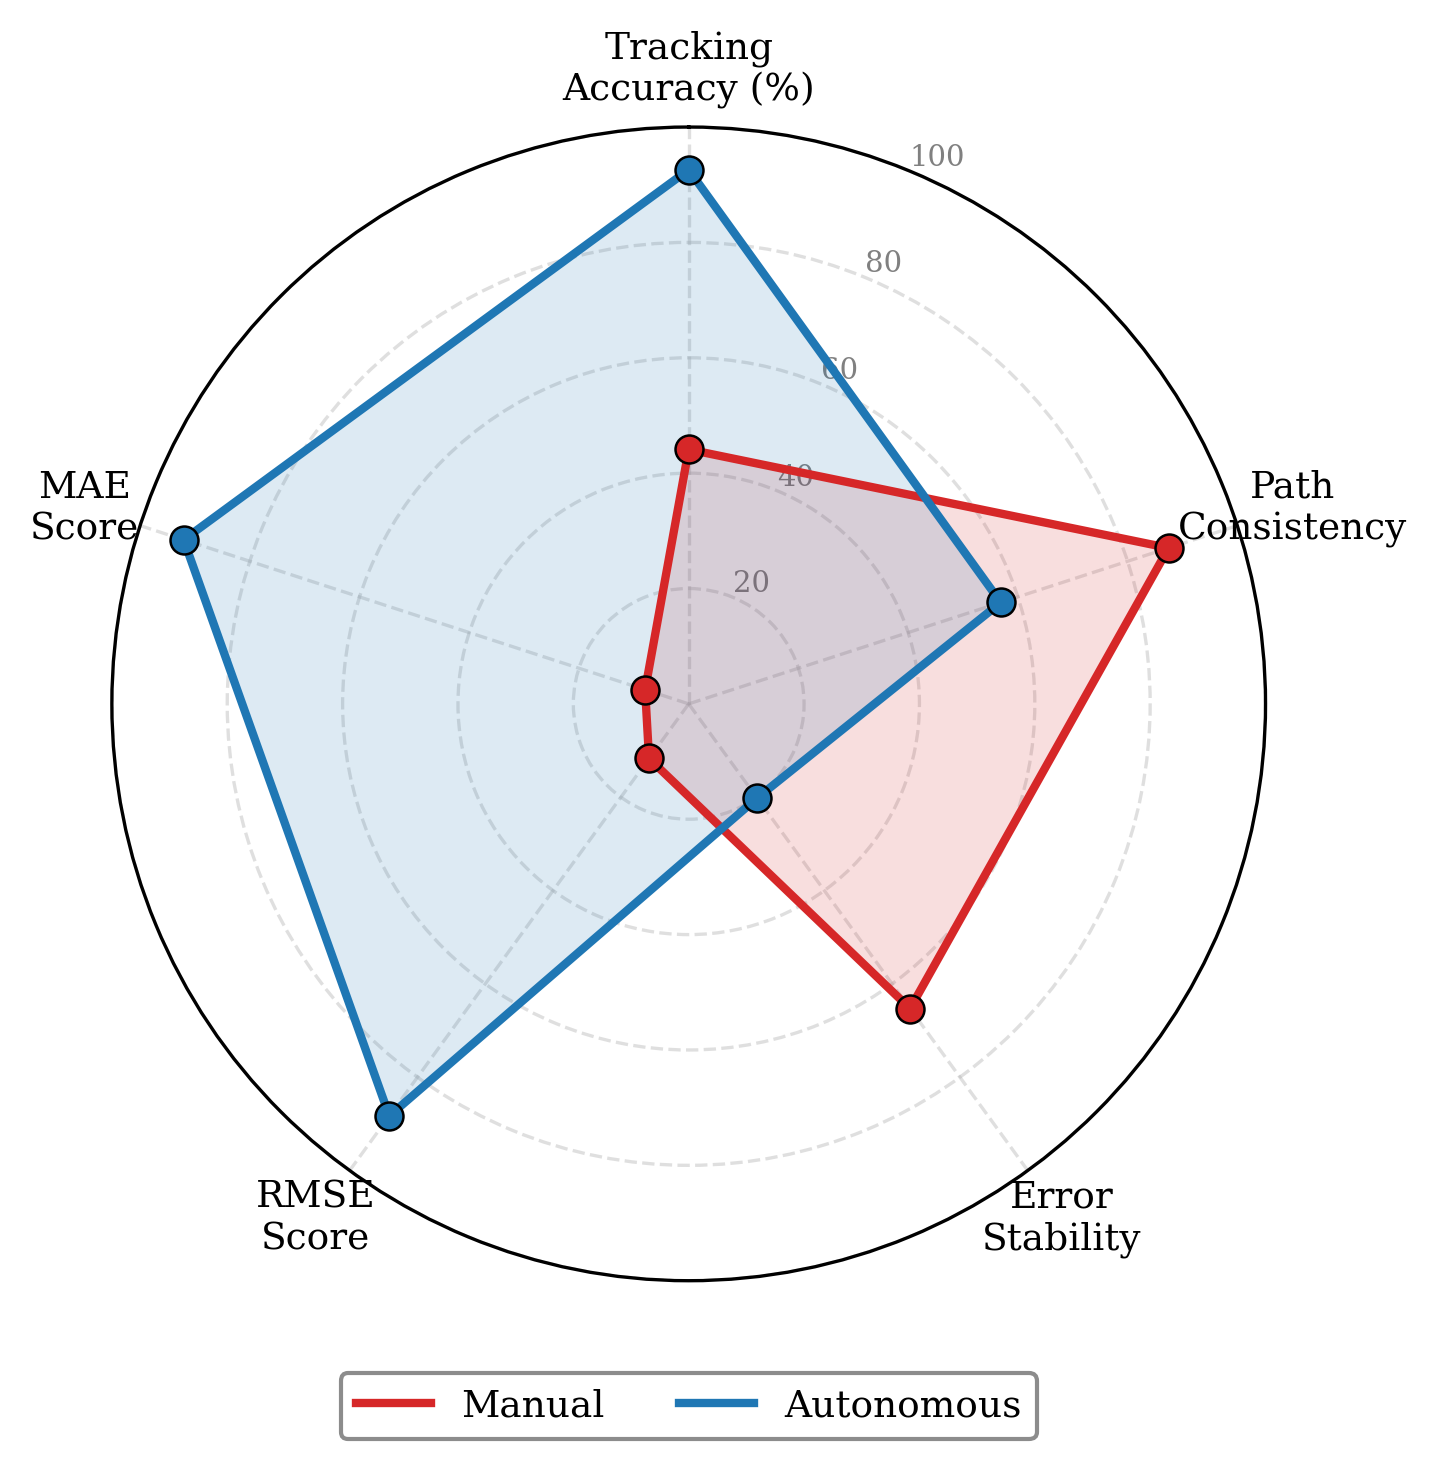

Saved → plot_radar.png


In [21]:
# ── CELL 15: Radar / Spider Chart ─────────────────────────────────────────────
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as pe

# ── Metrics (higher = better for all, so invert error-based ones) ─────────────
metrics = [
    "Tracking\nAccuracy (%)",
    "Path\nConsistency",
    "Error\nStability",
    "RMSE\nScore",
    "MAE\nScore",
]

# Normalise to [0, 100] where 100 = best possible
man_vals = np.array([
    man_acc.mean(),                                      # tracking accuracy
    (1 - man_rmse.std()  / man_rmse.mean())  * 100,     # consistency (low CV = good)
    (1 - man_std_per.mean() / man_rmse.mean()) * 100,   # error stability
    (1 - man_mean  / (man_mean  + auto_mean))  * 100,   # RMSE score
    (1 - man_mae_mean / (man_mae_mean + auto_mae_mean)) * 100,  # MAE score
])

auto_vals = np.array([
    auto_acc.mean(),
    (1 - auto_rmse.std()  / auto_rmse.mean())  * 100,
    (1 - auto_std_per.mean() / auto_rmse.mean()) * 100,
    (1 - auto_mean  / (man_mean  + auto_mean))  * 100,
    (1 - auto_mae_mean / (man_mae_mean + auto_mae_mean)) * 100,
])

# Clip to [0, 100]
man_vals  = np.clip(man_vals,  0, 100)
auto_vals = np.clip(auto_vals, 0, 100)

N      = len(metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]   # close polygon

man_plot  = man_vals.tolist()  + man_vals[:1].tolist()
auto_plot = auto_vals.tolist() + auto_vals[:1].tolist()

fig, ax = plt.subplots(figsize=(5, 5),
                        subplot_kw=dict(polar=True))

# Draw spokes and rings
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=9)
ax.set_ylim(0, 100)
ax.set_yticks([20, 40, 60, 80, 100])
ax.set_yticklabels(["20", "40", "60", "80", "100"], fontsize=7, color="grey")
ax.yaxis.grid(True,  linestyle="--", alpha=0.4)
ax.xaxis.grid(True,  linestyle="--", alpha=0.4)

# Manual
ax.plot(angles, man_plot,  color=C_MAN,  linewidth=2,   zorder=4,
        label="Manual")
ax.fill(angles, man_plot,  color=C_MAN,  alpha=0.15,    zorder=3)
ax.scatter(angles[:-1], man_vals,  color=C_MAN,  s=45,
           edgecolors="black", linewidths=0.6, zorder=5)

# Autonomous
ax.plot(angles, auto_plot, color=C_AUTO, linewidth=2,   zorder=4,
        label="Autonomous")
ax.fill(angles, auto_plot, color=C_AUTO, alpha=0.15,    zorder=3)
ax.scatter(angles[:-1], auto_vals, color=C_AUTO, s=45,
           edgecolors="black", linewidths=0.6, zorder=5)

ax.legend(frameon=True, framealpha=0.9, edgecolor="gray",
          loc="upper center", bbox_to_anchor=(0.5, -0.08),
          ncol=2, borderaxespad=0)

plt.tight_layout()
plt.savefig("plot_radar.png", bbox_inches="tight")
plt.show()
print("Saved → plot_radar.png")

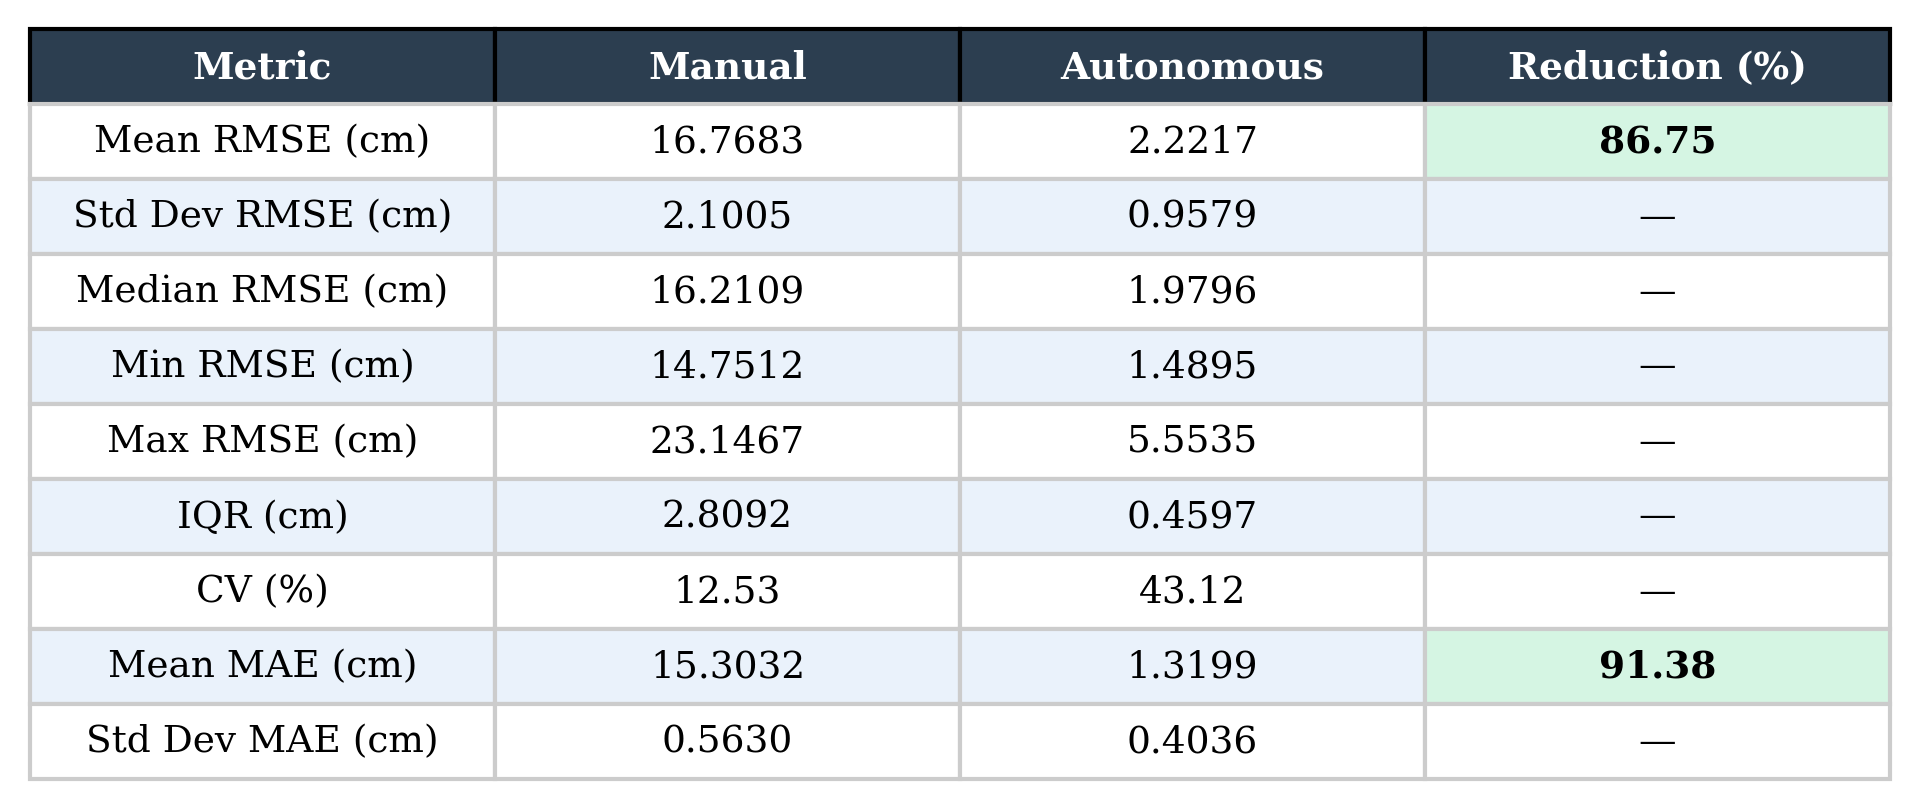

Saved → table1_descriptive.png


In [22]:
# ── CELL 16: Table 1 — Descriptive Statistics ─────────────────────────────────
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.axis("off")

col_labels = ["Metric", "Manual", "Autonomous", "Reduction (%)"]

rows = [
    ["Mean RMSE (cm)",    f"{man_mean:.4f}",     f"{auto_mean:.4f}",    f"{rmse_reduction_pct:.2f}"],
    ["Std Dev RMSE (cm)", f"{man_std:.4f}",      f"{auto_std:.4f}",     "—"],
    ["Median RMSE (cm)",  f"{man_median:.4f}",   f"{auto_median:.4f}",  "—"],
    ["Min RMSE (cm)",     f"{man_min:.4f}",      f"{auto_min:.4f}",     "—"],
    ["Max RMSE (cm)",     f"{man_max:.4f}",      f"{auto_max:.4f}",     "—"],
    ["IQR (cm)",          f"{man_iqr:.4f}",      f"{auto_iqr:.4f}",     "—"],
    ["CV (%)",            f"{man_cv:.2f}",        f"{auto_cv:.2f}",      "—"],
    ["Mean MAE (cm)",     f"{man_mae_mean:.4f}", f"{auto_mae_mean:.4f}",f"{mae_reduction_pct:.2f}"],
    ["Std Dev MAE (cm)",  f"{man_mae_std:.4f}",  f"{auto_mae_std:.4f}", "—"],
]

table = ax.table(
    cellText    = rows,
    colLabels   = col_labels,
    cellLoc     = "center",
    loc         = "center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

# Header style
for col in range(len(col_labels)):
    table[0, col].set_facecolor("#2C3E50")
    table[0, col].set_text_props(color="white", fontweight="bold")

# Alternating row colours
for row in range(1, len(rows) + 1):
    fc = "#EAF2FB" if row % 2 == 0 else "white"
    for col in range(len(col_labels)):
        table[row, col].set_facecolor(fc)
        table[row, col].set_edgecolor("#CCCCCC")

# Highlight reduction column
for row in range(1, len(rows) + 1):
    val = rows[row - 1][3]
    if val != "—":
        table[row, 3].set_facecolor("#D5F5E3")
        table[row, 3].set_text_props(fontweight="bold")

plt.tight_layout()
plt.savefig("table1_descriptive.png", bbox_inches="tight")
plt.show()
print("Saved → table1_descriptive.png")

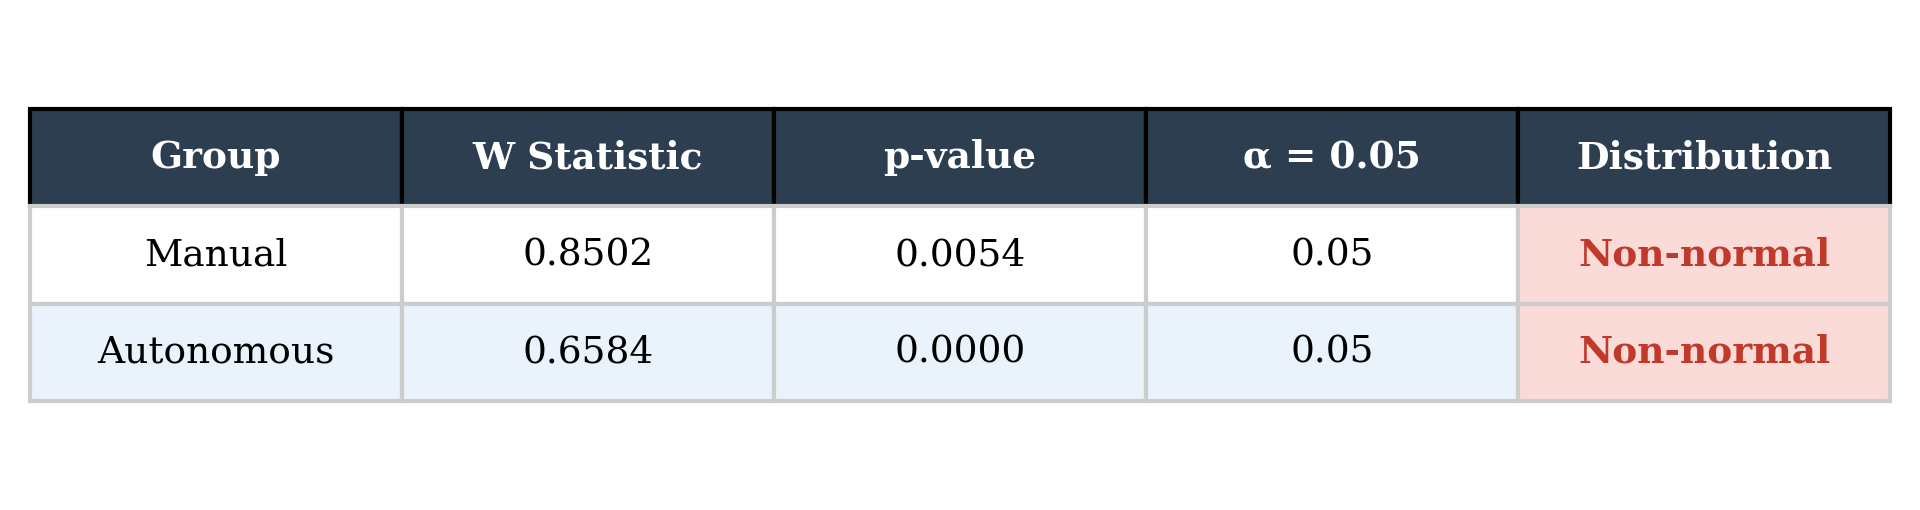

Saved → table2_normality.png


In [23]:
# ── CELL 17: Table 2 — Normality Test (Shapiro-Wilk) ─────────────────────────
fig, ax = plt.subplots(figsize=(6.5, 1.8))
ax.axis("off")

col_labels = ["Group", "W Statistic", "p-value", "α = 0.05", "Distribution"]

rows = [
    ["Manual",     f"{sw_man_stat:.4f}",  f"{sw_man_p:.4f}",
     "0.05", "Non-normal" if not man_normal  else "Normal"],
    ["Autonomous", f"{sw_auto_stat:.4f}", f"{sw_auto_p:.4f}",
     "0.05", "Non-normal" if not auto_normal else "Normal"],
]

table = ax.table(
    cellText  = rows,
    colLabels = col_labels,
    cellLoc   = "center",
    loc       = "center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

# Header
for col in range(len(col_labels)):
    table[0, col].set_facecolor("#2C3E50")
    table[0, col].set_text_props(color="white", fontweight="bold")

# Row colours
for row in range(1, len(rows) + 1):
    fc = "#EAF2FB" if row % 2 == 0 else "white"
    for col in range(len(col_labels)):
        table[row, col].set_facecolor(fc)
        table[row, col].set_edgecolor("#CCCCCC")

# Highlight distribution verdict
for row in range(1, len(rows) + 1):
    verdict = rows[row - 1][4]
    col_idx = 4
    if verdict == "Non-normal":
        table[row, col_idx].set_facecolor("#FADBD8")
        table[row, col_idx].set_text_props(fontweight="bold", color="#C0392B")
    else:
        table[row, col_idx].set_facecolor("#D5F5E3")
        table[row, col_idx].set_text_props(fontweight="bold", color="#1E8449")

plt.tight_layout()
plt.savefig("table2_normality.png", bbox_inches="tight")
plt.show()
print("Saved → table2_normality.png")

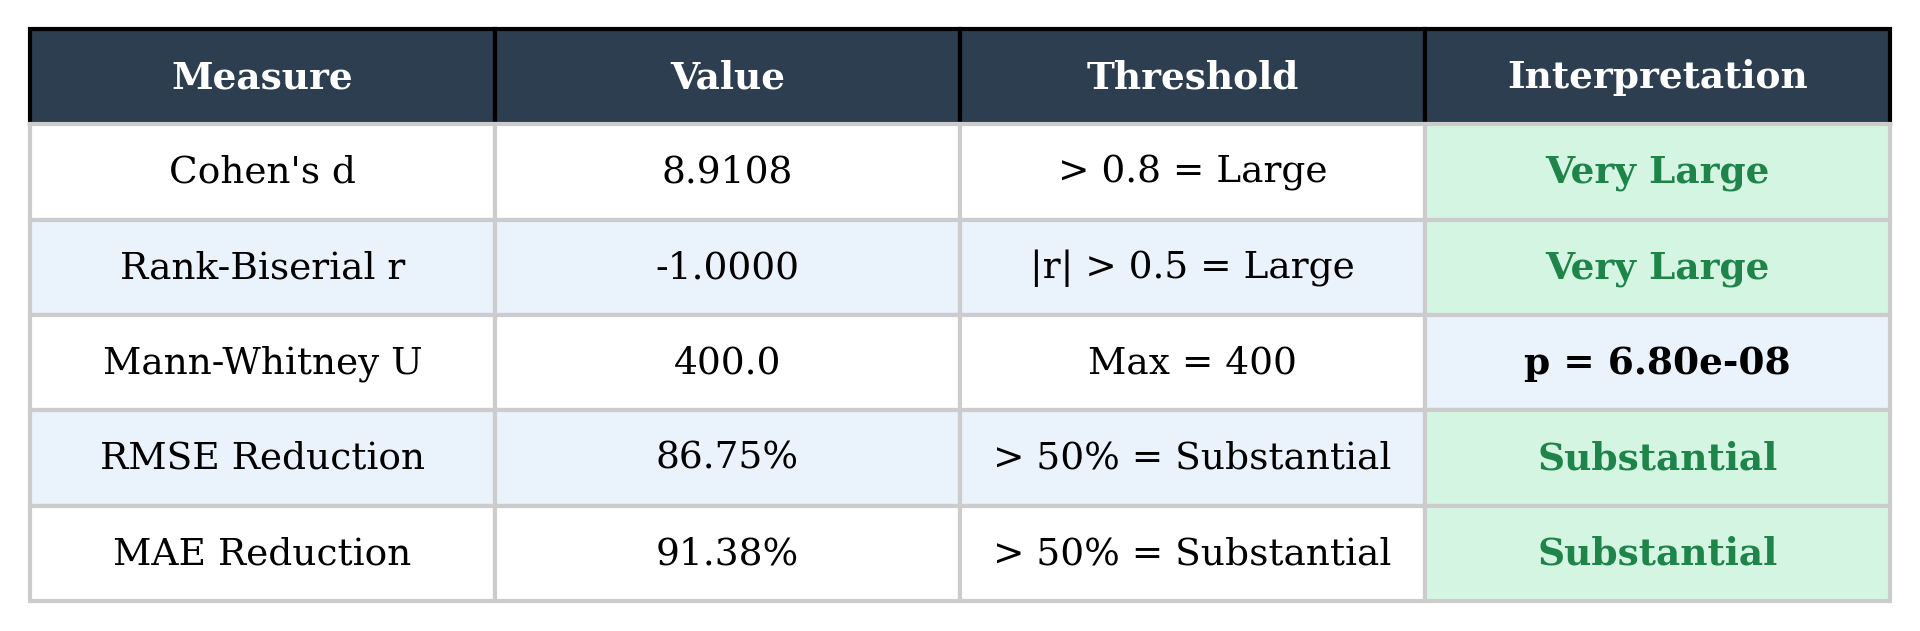

Saved → table4_effect_size.png


In [25]:
# ── CELL 19: Table 4 — Effect Size ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.axis("off")

col_labels = ["Measure", "Value", "Threshold", "Interpretation"]

rows = [
    ["Cohen's d",
     f"{cohens_d:.4f}",
     "> 0.8 = Large",
     "Very Large" if cohens_d > 2.0 else "Large" if cohens_d > 0.8 else "Medium"],

    ["Rank-Biserial r",
     f"{r_rb:.4f}",
     "|r| > 0.5 = Large",
     "Very Large" if abs(r_rb) > 0.7 else "Large" if abs(r_rb) > 0.5 else "Medium"],

    ["Mann-Whitney U",
     f"{u_stat:.1f}",
     f"Max = {len(man_rmse)*len(auto_rmse)}",
     f"p = {u_p:.2e}"],

    ["RMSE Reduction",
     f"{rmse_reduction_pct:.2f}%",
     "> 50% = Substantial",
     "Substantial" if rmse_reduction_pct > 50 else "Moderate"],

    ["MAE Reduction",
     f"{mae_reduction_pct:.2f}%",
     "> 50% = Substantial",
     "Substantial" if mae_reduction_pct > 50 else "Moderate"],
]

table = ax.table(
    cellText  = rows,
    colLabels = col_labels,
    cellLoc   = "center",
    loc       = "center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

# Header
for col in range(len(col_labels)):
    table[0, col].set_facecolor("#2C3E50")
    table[0, col].set_text_props(color="white", fontweight="bold")

# Row colours
for row in range(1, len(rows) + 1):
    fc = "#EAF2FB" if row % 2 == 0 else "white"
    for col in range(len(col_labels)):
        table[row, col].set_facecolor(fc)
        table[row, col].set_edgecolor("#CCCCCC")

# Highlight interpretation column
highlight_green = {"Very Large", "Substantial"}
for row in range(1, len(rows) + 1):
    verdict = rows[row - 1][3]
    if any(v in verdict for v in highlight_green):
        table[row, 3].set_facecolor("#D5F5E3")
        table[row, 3].set_text_props(fontweight="bold", color="#1E8449")
    elif "p =" in verdict:
        table[row, 3].set_facecolor("#EAF2FB")
        table[row, 3].set_text_props(fontweight="bold")

plt.tight_layout()
plt.savefig("table4_effect_size.png", bbox_inches="tight")
plt.show()
print("Saved → table4_effect_size.png")

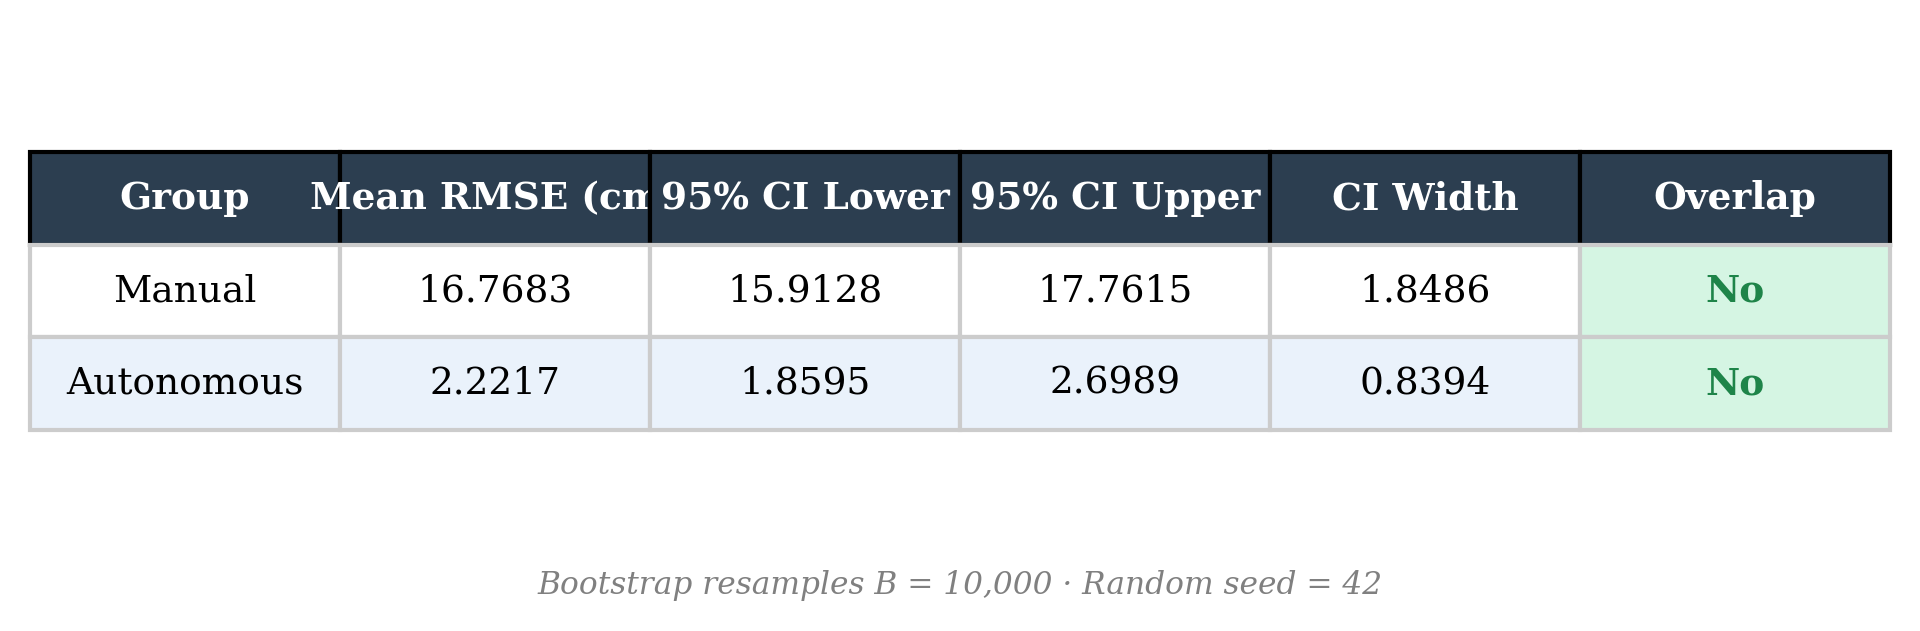

Saved → table5_bootstrap_ci.png


In [26]:
# ── CELL 20: Table 5 — Bootstrap 95% Confidence Intervals ────────────────────
fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.axis("off")

col_labels = ["Group", "Mean RMSE (cm)", "95% CI Lower", "95% CI Upper",
              "CI Width", "Overlap"]

ci_width_man  = man_ci[1]  - man_ci[0]
ci_width_auto = auto_ci[1] - auto_ci[0]
overlap       = "No" if man_ci[0] > auto_ci[1] or auto_ci[0] > man_ci[1] else "Yes"

rows = [
    ["Manual",
     f"{man_mean:.4f}",
     f"{man_ci[0]:.4f}",
     f"{man_ci[1]:.4f}",
     f"{ci_width_man:.4f}",
     overlap],

    ["Autonomous",
     f"{auto_mean:.4f}",
     f"{auto_ci[0]:.4f}",
     f"{auto_ci[1]:.4f}",
     f"{ci_width_auto:.4f}",
     overlap],
]

table = ax.table(
    cellText  = rows,
    colLabels = col_labels,
    cellLoc   = "center",
    loc       = "center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

# Header
for col in range(len(col_labels)):
    table[0, col].set_facecolor("#2C3E50")
    table[0, col].set_text_props(color="white", fontweight="bold")

# Row colours
for row in range(1, len(rows) + 1):
    fc = "#EAF2FB" if row % 2 == 0 else "white"
    for col in range(len(col_labels)):
        table[row, col].set_facecolor(fc)
        table[row, col].set_edgecolor("#CCCCCC")

# Highlight overlap column
for row in range(1, len(rows) + 1):
    val = rows[row - 1][5]
    if val == "No":
        table[row, 5].set_facecolor("#D5F5E3")
        table[row, 5].set_text_props(fontweight="bold", color="#1E8449")
    else:
        table[row, 5].set_facecolor("#FADBD8")
        table[row, 5].set_text_props(fontweight="bold", color="#C0392B")

# Bootstrap note
ax.text(0.5, -0.08, f"Bootstrap resamples B = 10,000 · Random seed = 42",
        transform=ax.transAxes, ha="center", fontsize=7.5,
        color="gray", style="italic")

plt.tight_layout()
plt.savefig("table5_bootstrap_ci.png", bbox_inches="tight")
plt.show()
print("Saved → table5_bootstrap_ci.png")

In [27]:
# ── CELL 21: Generate Full JSON + Zip All Data + Download ─────────────────────
import json, os, zipfile
from scipy import stats

# ── Per-trial metrics ─────────────────────────────────────────────────────────
def trial_metrics(df, err_col):
    e = df[err_col].abs()
    return {
        "rmse"  : float(np.sqrt((e**2).mean())),
        "mae"   : float(e.mean()),
        "std"   : float(e.std()),
        "min"   : float(e.min()),
        "max"   : float(e.max()),
        "median": float(e.median()),
        "p95"   : float(np.percentile(e, 95)),
        "rows"  : int(len(df)),
    }

man_trials  = [{"file": os.path.basename(f), **trial_metrics(df, "error_cm")}
               for f, df in zip(man_files, man_dfs)]

auto_trials = []
for f, df in zip(auto_files, auto_dfs):
    m = trial_metrics(df, "error_distance")
    m["file"]            = os.path.basename(f)
    m["tracking_pct"]    = float((df["control_state"] == "tracking").mean() * 100) \
                           if "control_state" in df.columns else 100.0
    m["mean_confidence"] = float(df["confidence"].mean()) if "confidence" in df.columns else None
    m["mean_steering"]   = float(df["steering"].mean())   if "steering"   in df.columns else None
    m["mean_speed"]      = float(df["speed"].mean())      if "speed"      in df.columns else None
    auto_trials.append(m)

# ── Arrays ────────────────────────────────────────────────────────────────────
man_rmse_arr  = np.array([t["rmse"] for t in man_trials])
auto_rmse_arr = np.array([t["rmse"] for t in auto_trials])
man_mae_arr   = np.array([t["mae"]  for t in man_trials])
auto_mae_arr  = np.array([t["mae"]  for t in auto_trials])
man_std_arr   = np.array([t["std"]  for t in man_trials])
auto_std_arr  = np.array([t["std"]  for t in auto_trials])
man_dev_arr   = np.array([df["deviation_angle"].abs().mean() for df in man_dfs])
auto_dev_arr  = np.array([df["deviation_angle"].abs().mean() for df in auto_dfs])

# ── Descriptive helper ────────────────────────────────────────────────────────
def desc(arr):
    return {
        "mean"  : float(arr.mean()),
        "std"   : float(arr.std()),
        "min"   : float(arr.min()),
        "max"   : float(arr.max()),
        "median": float(np.median(arr)),
        "q1"    : float(np.percentile(arr, 25)),
        "q3"    : float(np.percentile(arr, 75)),
        "iqr"   : float(np.percentile(arr, 75) - np.percentile(arr, 25)),
        "cv_pct": float(arr.std() / arr.mean() * 100),
        "p95"   : float(np.percentile(arr, 95)),
    }

# ── Normality ─────────────────────────────────────────────────────────────────
sw_m_w, sw_m_p = stats.shapiro(man_rmse_arr)
sw_a_w, sw_a_p = stats.shapiro(auto_rmse_arr)

# ── Significance ──────────────────────────────────────────────────────────────
t_s,  t_p  = stats.ttest_ind(man_rmse_arr, auto_rmse_arr, equal_var=False)
u_s,  u_p  = stats.mannwhitneyu(man_rmse_arr, auto_rmse_arr, alternative="two-sided")
pt_s, pt_p = stats.ttest_rel(man_rmse_arr, auto_rmse_arr)
ks_s, ks_p = stats.ks_2samp(man_rmse_arr, auto_rmse_arr)

# ── Effect size ───────────────────────────────────────────────────────────────
pooled_std = np.sqrt((man_rmse_arr.std()**2 + auto_rmse_arr.std()**2) / 2)
cohens_d_  = float((man_rmse_arr.mean() - auto_rmse_arr.mean()) / pooled_std)
r_rb_      = float(1 - (2 * u_s) / (len(man_rmse_arr) * len(auto_rmse_arr)))

# ── Bootstrap CI ─────────────────────────────────────────────────────────────
rng_ = np.random.default_rng(42)
B_, n_ = 10_000, len(man_rmse_arr)
bm = [rng_.choice(man_rmse_arr,  n_, replace=True).mean() for _ in range(B_)]
ba = [rng_.choice(auto_rmse_arr, n_, replace=True).mean() for _ in range(B_)]
m_ci = np.percentile(bm, [2.5, 97.5])
a_ci = np.percentile(ba, [2.5, 97.5])

# ── Accuracy ──────────────────────────────────────────────────────────────────
MAX_ERR = 30.0
man_acc_per  = ((1 - man_rmse_arr  / MAX_ERR) * 100).tolist()
auto_acc_per = ((1 - auto_rmse_arr / MAX_ERR) * 100).tolist()

# ── Reduction ─────────────────────────────────────────────────────────────────
rmse_red = float((1 - auto_rmse_arr.mean() / man_rmse_arr.mean()) * 100)
mae_red  = float((1 - auto_mae_arr.mean()  / man_mae_arr.mean())  * 100)
std_red  = float((1 - auto_std_arr.mean()  / man_std_arr.mean())  * 100)

# ── Assemble JSON ─────────────────────────────────────────────────────────────
data = {
    "meta": {
        "description"     : "Full statistical dataset — Manual vs Autonomous navigation",
        "manual_n"        : len(man_files),
        "autonomous_n"    : len(auto_files),
        "arena_length_cm" : 152.4,
        "arena_width_cm"  : 91.44,
        "max_error_ref_cm": MAX_ERR,
        "bootstrap_B"     : B_,
        "bootstrap_seed"  : 42,
    },
    "per_trial": {
        "manual"                    : man_trials,
        "autonomous"                : auto_trials,
        "improvement_per_trial_cm"  : (man_rmse_arr - auto_rmse_arr).tolist(),
        "man_accuracy_per_trial_pct": man_acc_per,
        "auto_accuracy_per_trial_pct": auto_acc_per,
    },
    "descriptive": {
        "manual_rmse"     : desc(man_rmse_arr),
        "auto_rmse"       : desc(auto_rmse_arr),
        "manual_mae"      : desc(man_mae_arr),
        "auto_mae"        : desc(auto_mae_arr),
        "manual_std"      : desc(man_std_arr),
        "auto_std"        : desc(auto_std_arr),
        "manual_dev_angle": desc(man_dev_arr),
        "auto_dev_angle"  : desc(auto_dev_arr),
    },
    "reduction": {
        "rmse_reduction_pct"  : rmse_red,
        "mae_reduction_pct"   : mae_red,
        "std_reduction_pct"   : std_red,
        "mean_improvement_cm" : float((man_rmse_arr - auto_rmse_arr).mean()),
        "total_improvement_cm": float((man_rmse_arr - auto_rmse_arr).sum()),
    },
    "accuracy": {
        "manual_mean_pct"    : float(np.mean(man_acc_per)),
        "autonomous_mean_pct": float(np.mean(auto_acc_per)),
        "manual_per_trial"   : man_acc_per,
        "auto_per_trial"     : auto_acc_per,
    },
    "normality_shapiro_wilk": {
        "manual"    : {"W": float(sw_m_w), "p": float(sw_m_p), "normal": bool(sw_m_p > 0.05)},
        "autonomous": {"W": float(sw_a_w), "p": float(sw_a_p), "normal": bool(sw_a_p > 0.05)},
    },
    "significance_tests": {
        "welch_t_test"  : {"t": float(t_s),  "p": float(t_p),
                           "significant": bool(t_p  < 0.05),
                           "note": "Two-sample Welch t-test (unequal variance)"},
        "mann_whitney_u": {"U": float(u_s),  "p": float(u_p),
                           "significant": bool(u_p  < 0.05),
                           "note": "Two-sided Mann-Whitney U (non-parametric)"},
        "paired_t_test" : {"t": float(pt_s), "p": float(pt_p),
                           "significant": bool(pt_p < 0.05),
                           "note": "Paired t-test (trial-matched)"},
        "ks_test"       : {"statistic": float(ks_s), "p": float(ks_p),
                           "significant": bool(ks_p < 0.05),
                           "note": "Two-sample Kolmogorov-Smirnov test"},
    },
    "effect_size": {
        "cohens_d"       : cohens_d_,
        "interpretation" : "Very Large" if cohens_d_ > 2.0 else "Large",
        "rank_biserial_r": r_rb_,
        "pooled_std"     : float(pooled_std),
    },
    "bootstrap_ci_95": {
        "manual"    : {"lower": float(m_ci[0]), "upper": float(m_ci[1]),
                       "width": float(m_ci[1] - m_ci[0])},
        "autonomous": {"lower": float(a_ci[0]), "upper": float(a_ci[1]),
                       "width": float(a_ci[1] - a_ci[0])},
        "overlap"   : bool(not (m_ci[0] > a_ci[1] or a_ci[0] > m_ci[1])),
    },
    "autonomous_specific": {
        "mean_tracking_pct"  : float(np.mean([t["tracking_pct"]    for t in auto_trials])),
        "mean_confidence"    : float(np.mean([t["mean_confidence"]  for t in auto_trials])),
        "mean_rows_per_trial": float(np.mean([t["rows"]             for t in auto_trials])),
        "mean_speed"         : float(np.mean([t["mean_speed"]       for t in auto_trials])),
    },
    "manual_specific": {
        "mean_rows_per_trial": float(np.mean([t["rows"] for t in man_trials])),
        "mean_dev_angle_deg" : float(man_dev_arr.mean()),
    },
    "best_worst": {
        "manual_best" : {"trial": man_trials[int(np.argmin(man_rmse_arr))]["file"],
                         "rmse" : float(man_rmse_arr.min())},
        "manual_worst": {"trial": man_trials[int(np.argmax(man_rmse_arr))]["file"],
                         "rmse" : float(man_rmse_arr.max())},
        "auto_best"   : {"trial": auto_trials[int(np.argmin(auto_rmse_arr))]["file"],
                         "rmse" : float(auto_rmse_arr.min())},
        "auto_worst"  : {"trial": auto_trials[int(np.argmax(auto_rmse_arr))]["file"],
                         "rmse" : float(auto_rmse_arr.max())},
    },
}

# ── Save JSON ─────────────────────────────────────────────────────────────────
JSON_PATH = "/content/comparison_full_data.json"
with open(JSON_PATH, "w") as f:
    json.dump(data, f, indent=2)
print(f"JSON saved → {JSON_PATH}  ({os.path.getsize(JSON_PATH)/1024:.1f} KB)")

# ── Zip JSON + all plots + all CSVs ──────────────────────────────────────────
ZIP_PATH = "/content/comparison_results.zip"
plots = [f for f in os.listdir("/content") if f.endswith(".png")]
csvs_man  = [os.path.join(MAN_DIR,  f) for f in os.listdir(MAN_DIR)  if f.endswith(".csv")]
csvs_auto = [os.path.join(AUTO_DIR, f) for f in os.listdir(AUTO_DIR) if f.endswith(".csv")]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(JSON_PATH, "comparison_full_data.json")
    for p in sorted(plots):
        z.write(f"/content/{p}", f"plots/{p}")
    for c in sorted(csvs_man):
        z.write(c, f"csv/manual/{os.path.basename(c)}")
    for c in sorted(csvs_auto):
        z.write(c, f"csv/autonomous/{os.path.basename(c)}")

print(f"Zip saved  → {ZIP_PATH}  ({os.path.getsize(ZIP_PATH)/1024/1024:.2f} MB)")
print(f"  JSON  : 1 file")
print(f"  Plots : {len(plots)} files")
print(f"  CSVs  : {len(csvs_man)+len(csvs_auto)} files")

# ── Download ──────────────────────────────────────────────────────────────────
from google.colab import files
files.download(ZIP_PATH)
print("Download started → comparison_results.zip")

JSON saved → /content/comparison_full_data.json  (22.8 KB)
Zip saved  → /content/comparison_results.zip  (3.38 MB)
  JSON  : 1 file
  Plots : 19 files
  CSVs  : 40 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started → comparison_results.zip
